# Explore performance evaluation summary results

In [17]:
import json
from pathlib import Path
import pandas as pd

LOGS_DIR = Path("../logs")

# ------------------------------------------------------------------
# Helper: conditional IPSNR (mean over samples with PP IoU > 0, plus n)
# ------------------------------------------------------------------
def conditional_ipsnr(csv_path, ipsnr_col="pp_ipsnr", iou_col="pp_iou"):
    if not csv_path.exists():
        return "N/A"
    df = pd.read_csv(csv_path)
    if ipsnr_col not in df.columns or iou_col not in df.columns:
        return "N/A"
    
    total_samples = len(df)
    subset = df.loc[df[iou_col] > 0, ipsnr_col]
    
    if len(subset) == 0 or total_samples == 0:
        return "N/A"
    
    # Fraction format: Mean (valid/total)
    return f"{subset.mean():.2f} ({len(subset)}/{total_samples})"


GROUPS = [
    {
        "header": "Direct (GOES->Landsat) - HAUNet",
        "order": [
            "e1_haunet_direct_focal_dice",
            "e1_haunet_direct_focal_dice_no_cov_encoder",
            "e1_haunet_direct_focal_dice_no_dem",
            "e1_haunet_direct_focal_dice_no_landcover",
            "e1_haunet_direct_focal_dice_dilated",
        ],
        "labels": {
            "e1_haunet_direct_focal_dice":               "E1: Full, No Target Dilation",
            "e1_haunet_direct_focal_dice_no_cov_encoder": "E1a: No Cov. Pyramid Enc.",
            "e1_haunet_direct_focal_dice_no_dem":         "E1b: No DEM",
            "e1_haunet_direct_focal_dice_no_landcover":   "E1c: No Land Cover",
            "e1_haunet_direct_focal_dice_dilated":        "E1d: Dilated Target",
        },
    },
    {
        "header": "Cascaded (GOES->VIIRS->Landsat) - HAUNet",
        "order": [
            "e2_haunet_cascaded_stage1_focal_dice",
            "e2_haunet_cascaded_stage1_focal_dice_dilated",
            "e2_haunet_cascaded_stage2_focal_dice_single_dilated",
            "e2_haunet_cascaded_stage2_focal_dice_double_dilated",
        ],
        "labels": {
            "e2_haunet_cascaded_stage1_focal_dice":                "E2.1a: Stage 1 (no dilation)",
            "e2_haunet_cascaded_stage1_focal_dice_dilated":        "E2.1b: Stage 1 (dilated)",
            "e2_haunet_cascaded_stage2_focal_dice_single_dilated": "E2.2a: Stage 2 (E2.1a input, dilated)",
            "e2_haunet_cascaded_stage2_focal_dice_double_dilated": "E2.2b: Stage 2 (E2.1b input dilated)",
        },
        # Split "best" comparison: Stage 1 rows compared only against each
        # other, Stage 2 rows compared only against each other.
        "subgroups": [
            ["e2_haunet_cascaded_stage1_focal_dice", "e2_haunet_cascaded_stage1_focal_dice_dilated"],
            ["e2_haunet_cascaded_stage2_focal_dice_single_dilated", "e2_haunet_cascaded_stage2_focal_dice_double_dilated"],
        ],
    },
    {
        "header": "Direct (GOES->Landsat) - Autoencoder",
        "order": [
            "e3_autoencoder_direct_focal_dice",
            "e3_autoencoder_direct_focal_dice_dilated",
        ],
        "labels": {
            "e3_autoencoder_direct_focal_dice":         "E3: Full, No Target Dilation",
            "e3_autoencoder_direct_focal_dice_dilated": "E3d: Dilated Target",
        },
    },
    {
        "header": "Cascaded pipeline - Autoencoder",
        "order": [
            "e4_autoencoder_cascaded_stage1_focal_dice",
            "e4_autoencoder_cascaded_stage2_focal_dice_v2",
            "e4_autoencoder_cascaded_stage2_focal_dice_dilated_v2",
        ],
        "labels": {
            "e4_autoencoder_cascaded_stage1_focal_dice": "E4.1: Stage 1 (no dilation)",
            "e4_autoencoder_cascaded_stage2_focal_dice_v2": "E4.2a: Stage 2 (no dilation)",
            "e4_autoencoder_cascaded_stage2_focal_dice_dilated_v2": "E4.2b: Stage 2 (dilated targets)",
        },
        "subgroups": [
            ["e4_autoencoder_cascaded_stage1_focal_dice"],
            ["e4_autoencoder_cascaded_stage2_focal_dice_v2", "e4_autoencoder_cascaded_stage2_focal_dice_dilated_v2"],
        ],
    },
]

COLUMN_ORDER = ["auprc", "iou (Post-PP)", "precision (Post-PP)", "recall (Post-PP)", "boundary_f1 (Post-PP)"]
COLUMN_LABELS = {
    "auprc": "AUPRC",
    "iou (Post-PP)": "IoU",
    "precision (Post-PP)": "Precision",
    "recall (Post-PP)": "Recall",
    "boundary_f1 (Post-PP)": "Boundary F1",
}

In [18]:
# ------------------------------------------------------------------
# Load every summary JSON once, keyed by experiment name
# ------------------------------------------------------------------
all_json_files = sorted(LOGS_DIR.glob("*best_val_auprc*.json"))
experiments = {}
baseline_all_zero = {}
baseline_prevalence = {}

for file in all_json_files:
    with open(file, "r") as f:
        content = json.load(f)
    exp_name = content.get("experiment", "")
    metrics = content.get("metrics", {})
    per_sample_csv = LOGS_DIR / file.name.replace("_test_summary.json", "_test_per_sample.csv")

    experiments[exp_name] = {
        "auprc": metrics.get("auprc", {}).get("mean"),
        "iou (Post-PP)": metrics.get("pp_iou", {}).get("mean"),
        "precision (Post-PP)": metrics.get("pp_precision", {}).get("mean"),
        "recall (Post-PP)": metrics.get("pp_recall", {}).get("mean"),
        "boundary_f1 (Post-PP)": metrics.get("pp_boundary_f1", {}).get("mean"),
        #"ipsnr": conditional_ipsnr(per_sample_csv),
    }

    if not baseline_all_zero:
        b_zero = content.get("baseline_all_zero", {})
        baseline_all_zero = {
            "auprc": b_zero.get("auprc", {}).get("mean"),
            "iou (Post-PP)": b_zero.get("iou", {}).get("mean"),
            "precision (Post-PP)": b_zero.get("precision", {}).get("mean"),
            "recall (Post-PP)": b_zero.get("recall", {}).get("mean"),
            "boundary_f1 (Post-PP)": None,
            #"ipsnr": None,
        }
    if not baseline_prevalence:
        b_prev = content.get("baseline_prevalence_rate", {})
        baseline_prevalence = {
            "auprc": b_prev.get("auprc", {}).get("mean"),
            "iou (Post-PP)": b_prev.get("iou", {}).get("mean"),
            "precision (Post-PP)": b_prev.get("precision", {}).get("mean"),
            "recall (Post-PP)": b_prev.get("recall", {}).get("mean"),
            "boundary_f1 (Post-PP)": None,
            #"ipsnr": None,
        }

In [19]:
# ------------------------------------------------------------------
# Build LaTeX body manually: section header rows + data rows
# ------------------------------------------------------------------
def fmt(val, is_best=False):
    if val is None or (isinstance(val, float) and pd.isna(val)):
        return "N/A"
    if isinstance(val, str):
        return f"\\textbf{{{val}}}" if is_best else val
    return f"\\textbf{{{val:.4f}}}" if is_best else f"{val:.4f}"

lines = []
lines.append(r"\begin{table}[htbp]")
lines.append(r"\centering")
lines.append(r"\footnotesize")
lines.append(r"\caption{Model performance evaluation across feature ablations vs. fixed baselines. Precision, Recall, Boundary F1 are computed on Otsu-thresholded predictions. Bold indicates the best value for that metric among the shown ablations of the same architecture and target}")
lines.append(r"\label{tab:all_results}")
lines.append(r"\begin{tabularx}{\textwidth}{lYYYYYY}")
lines.append(r"\hline")
header_row = " & ".join(["\\textbf{Exp.}"] + [f"\\textbf{{{COLUMN_LABELS[c]}}}" for c in COLUMN_ORDER])
lines.append(header_row + r" \\ \hline")

for i, group in enumerate(GROUPS):
    if i > 0:
        lines.append(r"\hline")
    lines.append(f"\\multicolumn{{{len(COLUMN_ORDER)+1}}}{{l}}{{\\textit{{{group['header']}}}}} \\\\")
    partitions = group.get("subgroups", [group["order"]])
    best_per_col = {}

    for sub in partitions:
        sub_rows = {eid: experiments[eid] for eid in sub if eid in experiments}
        # Only compute a "best" if there's more than one valid experiment
        # to compare — a single-row subgroup has no ablation comparison,
        # so nothing should be bolded.
        has_comparison = len(sub_rows) > 1
        for col in COLUMN_ORDER:
            if has_comparison:
                vals = [r.get(col) for r in sub_rows.values()
                         if isinstance(r.get(col), (int, float)) and not pd.isna(r.get(col))]
                max_val = max(vals) if vals else None
            else:
                max_val = None  # no comparison possible -> never bold
            for eid in sub:
                best_per_col.setdefault(eid, {})[col] = max_val

    for eid in group["order"]:
        if eid not in experiments:
            print(f"[warn] missing data for {eid}")
            continue
        row = experiments[eid]
        label = group["labels"].get(eid, eid.replace("_", r"\_"))
        cells = [label]
        for col in COLUMN_ORDER:
            v = row.get(col)
            # Safely fetch target best for this specific experiment ID
            target_best = best_per_col.get(eid, {}).get(col)
            is_best = (col != "ipsnr") and (target_best is not None) and (v == target_best)
            cells.append(fmt(v, is_best=is_best))
        lines.append(" & ".join(cells) + r" \\")

# Baseline rows
lines.append(r"\hline")    
for name, b in [("Baseline: All-Zero", baseline_all_zero), ("Baseline: Prevalence-Rate", baseline_prevalence)]:
    cells = [name] + [fmt(b.get(col)) for col in COLUMN_ORDER]
    lines.append(" & ".join(cells) + r" \\")

lines.append(r"\hline")
lines.append(r"\end{tabularx}")
lines.append(r"\end{table}")

full_latex_table = "\n".join(lines)

In [46]:
# ------------------------------------------------------------------
# Cross-group summary: best experiment per GROUP (by primary metric),
# for direct architecture/pipeline comparison. E2 (cascaded HAUNet)
# mixes Stage 1 (VIIRS target) and Stage 2 (Landsat target) experiments,
# which predict different things and aren't directly comparable — so it
# is split into two summary rows instead of one.
# ------------------------------------------------------------------
PRIMARY_METRIC = "auprc"

def best_in(eids):
    valid = {eid: experiments[eid] for eid in eids
             if eid in experiments
             and isinstance(experiments[eid].get(PRIMARY_METRIC), (int, float))
             and not pd.isna(experiments[eid].get(PRIMARY_METRIC))}
    if not valid:
        return None
    return max(valid, key=lambda k: valid[k][PRIMARY_METRIC])

FORCED_BEST = {
    "Cascaded - Autoencoder": "e4_autoencoder_cascaded_stage2_focal_dice_dilated_v2",
}

summary_specs = [
    ("Direct - HAUNet",            [eid for eid in GROUPS[0]["order"]], GROUPS[0]["labels"]),
    # REMOVED: ("Cascaded Stage 1 - HAUNet",  GROUPS[1]["subgroups"][0], GROUPS[1]["labels"]),
    ("Cascaded - HAUNet",  GROUPS[1]["subgroups"][1],           GROUPS[1]["labels"]),
    ("Direct - Autoencoder",       GROUPS[2]["order"],                  GROUPS[2]["labels"]),
    ("Cascaded - Autoencoder",     GROUPS[3]["order"],                  GROUPS[3]["labels"]),
]

# --- NEW: lookup table mapping exp_id -> (mean, lo, hi) for AUPRC CI ---
auprc_ci_lookup = {}
for label, row in results.items():
    if "auprc_ci" in row:
        exp_name = row["prefix"].replace("_best_val_auprc", "")
        auprc_ci_lookup[exp_name] = row["auprc_ci"]  # (mean, lo, hi)

def fmt_auprc_with_ci(exp_id, val, is_best=False):
    if val is None or (isinstance(val, float) and pd.isna(val)):
        return "N/A"
    base = f"{val:.4f}"
    ci = auprc_ci_lookup.get(exp_id)
    if ci is not None:
        _, lo, hi = ci
        base = f"{val:.4f} [{lo:.4f}, {hi:.4f}]"
    return f"\\textbf{{{base}}}" if is_best else base
# --- end new ---

summary_rows = []
for header, eids, labels in summary_specs:
    short_code = label.split(":")[0].strip() if ":" in label else label
    cells = [f"{header} ({short_code})"]
    if header in FORCED_BEST:
        best_eid = FORCED_BEST[header]
        if best_eid not in experiments:
            print(f"[warn] forced eid {best_eid} not found in experiments")
            continue
    else:
        best_eid = best_in(eids)
    if best_eid is None:
        print(f"[warn] no valid data for summary group: {header}")
        continue
    # CHANGED: now stores best_eid alongside label and row
    summary_rows.append((header, best_eid, labels.get(best_eid, best_eid.replace("_", r"\_")), experiments[best_eid]))

# Bold the best value per column, across these summary rows only
summary_best_per_col = {}
for col in COLUMN_ORDER:
    if col == "ipsnr":
        continue
    # CHANGED: unpack 4-tuple now
    vals = [r.get(col) for _, _, _, r in summary_rows
             if isinstance(r.get(col), (int, float)) and not pd.isna(r.get(col))]
    summary_best_per_col[col] = max(vals) if vals else None

summary_lines = []
summary_lines.append(r"\begin{table}[htbp]")
summary_lines.append(r"\centering")
summary_lines.append(r"\footnotesize")
summary_lines.append(r"\caption{Best-performing configuration (by AUPRC) within each architecture/pipeline group, for direct cross-group comparison. AUPRC values shown with 95\% bootstrap confidence intervals.}")
summary_lines.append(r"\label{tab:best_overall}")
summary_lines.append(r"\begin{tabularx}{\textwidth}{p{3.2cm}YYYYY}")
summary_lines.append(r"\hline")
summary_header = " & ".join(["\\textbf{Group}"] + [f"\\textbf{{{COLUMN_LABELS[c]}}}" for c in COLUMN_ORDER])
summary_lines.append(summary_header + r" \\ \hline")
# CHANGED: unpack 4-tuple, and use fmt_auprc_with_ci for the auprc column
for header, best_eid, label, row in summary_rows:
    cells = [f"{header} ({label})"]
    for col in COLUMN_ORDER:
        v = row.get(col)
        is_best = (col != "ipsnr") and (summary_best_per_col.get(col) is not None) and (v == summary_best_per_col[col])
        if col == "auprc":
            cells.append(fmt_auprc_with_ci(best_eid, v, is_best=is_best))
        else:
            cells.append(fmt(v, is_best=is_best))
    summary_lines.append(" & ".join(cells) + r" \\")
summary_lines.append(r"\hline")
summary_lines.append(r"\end{tabularx}")
summary_lines.append(r"\end{table}")
full_summary_table = "\n".join(summary_lines)

In [28]:
# ------------------------------------------------------------------
# Notebook preview: flat DataFrame view with per-group best highlighted
# ------------------------------------------------------------------
preview_rows = []

for group in GROUPS:
    for eid in group["order"]:
        if eid not in experiments:
            continue
        row = experiments[eid]
        label = group["labels"].get(eid, eid)
        preview_rows.append({
            "Group": group["header"],
            "Experiment": label,
            **row,
        })

for name, b in [("Baseline: All-Zero", baseline_all_zero), ("Baseline: Prevalence-Rate", baseline_prevalence)]:
    preview_rows.append({"Group": "Baselines", "Experiment": name, **b})

preview_df = pd.DataFrame(preview_rows).set_index(["Group", "Experiment"])
preview_df = preview_df.reindex(columns=COLUMN_ORDER)
preview_df.columns = [COLUMN_LABELS[c] for c in COLUMN_ORDER]

numeric_preview_cols = [COLUMN_LABELS[c] for c in COLUMN_ORDER if c != "ipsnr"]

subgroup_map = {}
for g in GROUPS:
    for idx, sub in enumerate(g.get("subgroups", [g["order"]])):
        for eid in sub:
            subgroup_map[g["labels"].get(eid, eid)] = f"{g['header']}_{idx}"

def highlight_best_per_group(df):
    styles = pd.DataFrame("", index=df.index, columns=df.columns)
    mapped_groups = pd.Series(df.index.get_level_values("Experiment")).map(subgroup_map).values

    for sg_id in set(mapped_groups):
        if pd.isna(sg_id):
            continue
        mask = mapped_groups == sg_id
        group_slice = df.iloc[mask]

        for col in numeric_preview_cols:
            col_vals = group_slice[col].dropna()
            if len(col_vals) <= 1:
                continue  # no comparison possible with 0 or 1 valid values
            best_val = col_vals.max()
            for idx in col_vals[col_vals == best_val].index:
                styles.loc[idx, col] = "background-color: lightgreen"
    return styles

print("--- Consolidated Results Preview (matches exported LaTeX table) ---")
display(
    preview_df.style
    .apply(highlight_best_per_group, axis=None)
    .format({col: "{:.4f}" for col in numeric_preview_cols}, na_rep="N/A")
    #.format({COLUMN_LABELS["ipsnr"]: lambda x: "N/A" if pd.isna(x) else str(x)})
)

--- Consolidated Results Preview (matches exported LaTeX table) ---


In [34]:
# ------------------------------------------------------------------
# Export
# ------------------------------------------------------------------
PROJECT_ROOT = Path("..").resolve()
output_dir = PROJECT_ROOT / "deliverables" / "tables"
output_dir.mkdir(parents=True, exist_ok=True)
tex_path = output_dir / "evaluation_table.tex"

with open(tex_path, "w") as f:
    f.write(full_latex_table)

print(f"Successfully generated consolidated LaTeX table at: {tex_path}")
print(full_latex_table)

Successfully generated consolidated LaTeX table at: /home/jupyter/irp-th25/deliverables/tables/evaluation_table.tex
\begin{table}[htbp]
\centering
\footnotesize
\caption{Model performance evaluation across feature ablations vs. fixed baselines. Precision, Recall, Boundary F1 are computed on Otsu-thresholded predictions. Bold indicates the best value for that metric among the shown ablations of the same architecture and target}
\label{tab:all_results}
\begin{tabularx}{\textwidth}{lYYYYYY}
\hline
\textbf{Exp.} & \textbf{AUPRC} & \textbf{IoU} & \textbf{Precision} & \textbf{Recall} & \textbf{Boundary F1} \\ \hline
\multicolumn{6}{l}{\textit{Direct (GOES->Landsat) - HAUNet}} \\
E1: Full, No Target Dilation & 0.0103 & 0.0021 & 0.0021 & 0.3403 & 0.0030 \\
E1a: No Cov. Pyramid Enc. & 0.0098 & 0.0043 & 0.0043 & 0.4605 & 0.0039 \\
E1b: No DEM & 0.0050 & 0.0020 & 0.0020 & 0.3100 & 0.0033 \\
E1c: No Land Cover & 0.0054 & 0.0026 & 0.0026 & \textbf{0.5051} & 0.0020 \\
E1d: Dilated Target & \textbf{0

In [47]:
summary_tex_path = output_dir / "evaluation_summary_table.tex"
with open(summary_tex_path, "w") as f:
    f.write(full_summary_table)
print(f"Successfully generated cross-group summary table at: {summary_tex_path}")
print(full_summary_table)

Successfully generated cross-group summary table at: /home/jupyter/irp-th25/deliverables/tables/evaluation_summary_table.tex
\begin{table}[htbp]
\centering
\footnotesize
\caption{Best-performing configuration (by AUPRC) within each architecture/pipeline group, for direct cross-group comparison. AUPRC values shown with 95\% bootstrap confidence intervals.}
\label{tab:best_overall}
\begin{tabularx}{\textwidth}{p{3.2cm}YYYYY}
\hline
\textbf{Group} & \textbf{AUPRC} & \textbf{IoU} & \textbf{Precision} & \textbf{Recall} & \textbf{Boundary F1} \\ \hline
Direct - HAUNet (E1d: Dilated Target) & \textbf{0.0188 [0.0084, 0.0336]} & 0.0044 & 0.0044 & 0.3490 & 0.0041 \\
Cascaded - HAUNet (E2.2a: Stage 2 (E2.1a input, dilated)) & 0.0142 [0.0071, 0.0237] & \textbf{0.0072} & 0.0074 & 0.2065 & \textbf{0.0071} \\
Direct - Autoencoder (E3: Full, No Target Dilation) & 0.0120 [0.0044, 0.0243] & 0.0064 & \textbf{0.0077} & 0.2592 & 0.0050 \\
Cascaded - Autoencoder (E4.2b: Stage 2 (dilated targets)) & 0.0106 [

In [48]:
import pandas as pd
import re

def latex_table_to_df(tex_str):
    rows = []
    for line in tex_str.splitlines():
        line = line.strip()
        if "&" in line and not line.startswith("%"):
            # strip trailing \\ and LaTeX line-end artifacts
            clean = line.replace("\\\\", "").strip()
            cells = [c.strip() for c in clean.split("&")]
            rows.append(cells)
    return pd.DataFrame(rows)

df_preview = latex_table_to_df(full_summary_table)
df_preview

,0,1,2,3,4,5
0,\textbf{Group},\textbf{AUPRC},\textbf{IoU},\textbf{Precision},\textbf{Recall},\textbf{Boundary F1} \hline
1,Direct - HAUNet (E1d: Dilated Target),"\textbf{0.0188 [0.0084, 0.0336]}",0.0044,0.0044,0.3490,0.0041
2,Cascaded - HAUNet (E2.2a: Stage 2 (E2.1a input...,"0.0142 [0.0071, 0.0237]",\textbf{0.0072},0.0074,0.2065,\textbf{0.0071}
3,"Direct - Autoencoder (E3: Full, No Target Dila...","0.0120 [0.0044, 0.0243]",0.0064,\textbf{0.0077},0.2592,0.0050
4,Cascaded - Autoencoder (E4.2b: Stage 2 (dilate...,"0.0106 [0.0044, 0.0184]",0.0056,0.0058,\textbf{0.4565},0.0040


### More results steps

In [13]:
import numpy as np

HEADLINE = {
    "E1d":   "e1_haunet_direct_focal_dice_dilated_best_val_auprc",
    "E2.2a": "e2_haunet_cascaded_stage2_focal_dice_single_dilated_best_val_auprc",
    "E3":    "e3_autoencoder_direct_focal_dice_best_val_auprc",
    "E4.2b": "e4_autoencoder_cascaded_stage2_focal_dice_dilated_v2_best_val_auprc",
}

def load_per_sample(exp_prefix):
    csv_path = LOGS_DIR / f"{exp_prefix}_test_per_sample.csv"
    if not csv_path.exists():
        return None
    return pd.read_csv(csv_path)

def bootstrap_ci(values, n_boot=1000, ci=95, seed=0):
    values = np.asarray(values)
    values = values[~np.isnan(values)]
    if len(values) == 0:
        return None, None, None
    rng = np.random.default_rng(seed)
    boot_means = np.array([
        rng.choice(values, size=len(values), replace=True).mean()
        for _ in range(n_boot)
    ])
    lo, hi = np.percentile(boot_means, [(100-ci)/2, 100-(100-ci)/2])
    return values.mean(), lo, hi

results = {}
for label, prefix in HEADLINE.items():
    df = load_per_sample(prefix)
    exp_name_lookup = prefix.replace("_best_val_auprc", "")
    summary = experiments.get(exp_name_lookup, {})

    row = {"label": label, "prefix": prefix}

    # --- Area inflation: ratio-of-means (from summary) ---
    prec_mean = summary.get("precision (Post-PP)")
    rec_mean = summary.get("recall (Post-PP)")
    row["inflation_ratio_of_means"] = (rec_mean / prec_mean) if prec_mean else None

    # --- Normalized AUPRC ---
    prevalence_auprc = baseline_prevalence.get("auprc")
    row["auprc"] = summary.get("auprc")
    row["auprc_normalized"] = (row["auprc"] / prevalence_auprc) if (row["auprc"] and prevalence_auprc) else None

    if df is not None:
        # --- Area inflation: per-patch median (only patches with actual precision>0) ---
        valid = df[df["pp_precision"] > 0]
        per_patch_ratio = valid["pp_recall"] / valid["pp_precision"]
        row["inflation_median_per_patch"] = per_patch_ratio.median()
        row["inflation_mean_per_patch"] = per_patch_ratio.mean()
        row["n_patches_with_pred"] = len(valid)
        row["n_patches_total"] = len(df)

        # --- Bootstrap CIs ---
        for metric_col, out_name in [
            ("auprc", "auprc_ci"),
            ("pp_iou", "iou_ci"),
            ("pp_precision", "precision_ci"),
            ("pp_recall", "recall_ci"),
            ("pp_boundary_f1", "boundary_f1_ci"),
        ]:
            mean, lo, hi = bootstrap_ci(df[metric_col].values)
            row[out_name] = (mean, lo, hi)
    else:
        print(f"[warn] no per-sample CSV for {label} ({prefix})")

    results[label] = row

# --- Print everything ---
for label, row in results.items():
    print(f"\n=== {label} ({row['prefix']}) ===")
    print(f"  AUPRC: {row['auprc']:.4f}  |  Normalized (x baseline): {row['auprc_normalized']:.1f}x" if row.get('auprc_normalized') else f"  AUPRC: {row.get('auprc')}")
    print(f"  Inflation (ratio of means): {row.get('inflation_ratio_of_means')}")
    if "inflation_median_per_patch" in row:
        print(f"  Inflation (per-patch median): {row['inflation_median_per_patch']:.2f}  (mean: {row['inflation_mean_per_patch']:.2f}, n={row['n_patches_with_pred']}/{row['n_patches_total']} patches with pred>0)")
    for ci_name in ["auprc_ci", "iou_ci", "precision_ci", "recall_ci", "boundary_f1_ci"]:
        if ci_name in row:
            mean, lo, hi = row[ci_name]
            print(f"  {ci_name}: {mean:.4f} [{lo:.4f}, {hi:.4f}]")


=== E1d (e1_haunet_direct_focal_dice_dilated_best_val_auprc) ===
  AUPRC: 0.0188  |  Normalized (x baseline): 30.4x
  Inflation (ratio of means): 78.84181825503195
  Inflation (per-patch median): 203.48  (mean: 439.26, n=64/121 patches with pred>0)
  auprc_ci: 0.0188 [0.0084, 0.0336]
  iou_ci: 0.0044 [0.0027, 0.0067]
  precision_ci: 0.0044 [0.0028, 0.0067]
  recall_ci: 0.3490 [0.2796, 0.4224]
  boundary_f1_ci: 0.0041 [0.0026, 0.0059]

=== E2.2a (e2_haunet_cascaded_stage2_focal_dice_single_dilated_best_val_auprc) ===
  AUPRC: 0.0142  |  Normalized (x baseline): 23.0x
  Inflation (ratio of means): 27.786593747457935
  Inflation (per-patch median): 39.04  (mean: 157.08, n=40/121 patches with pred>0)
  auprc_ci: 0.0142 [0.0071, 0.0237]
  iou_ci: 0.0072 [0.0038, 0.0115]
  precision_ci: 0.0074 [0.0039, 0.0120]
  recall_ci: 0.2065 [0.1452, 0.2760]
  boundary_f1_ci: 0.0071 [0.0041, 0.0107]

=== E3 (e3_autoencoder_direct_focal_dice_best_val_auprc) ===
  AUPRC: 0.0120  |  Normalized (x baseline

In [16]:
def run_paired_test(label_a, label_b):
    prefix_a = HEADLINE[label_a]
    prefix_b = HEADLINE[label_b]
    df_a = load_per_sample(prefix_a).set_index("sample_id")
    df_b = load_per_sample(prefix_b).set_index("sample_id")
    common_ids = df_a.index.intersection(df_b.index)
    print(f"{label_a} vs {label_b}: {len(common_ids)} common patches "
          f"(A has {len(df_a)}, B has {len(df_b)})")

    mean_diff, lo, hi, frac_a_greater = paired_bootstrap_diff(
        df_a.loc[common_ids, "auprc"].values,
        df_b.loc[common_ids, "auprc"].values
    )
    print(f"  AUPRC diff ({label_a} - {label_b}): {mean_diff:.4f} "
          f"[{lo:.4f}, {hi:.4f}]  P({label_a}>{label_b}): {frac_a_greater:.1%}")
    return mean_diff, lo, hi, frac_a_greater

print("--- HAUNet vs Autoencoder ---")
run_paired_test("E1d", "E3")      # direct
run_paired_test("E2.2a", "E4.2b") # cascaded

print("\n--- Cascaded vs Direct (within architecture) ---")
run_paired_test("E2.2a", "E1d")   # HAUNet: cascaded vs direct
# Note: no cascaded/direct pair for Autoencoder in HEADLINE currently —
# E4.2b vs E3 covers this if you want it too:
run_paired_test("E4.2b", "E3")

--- HAUNet vs Autoencoder ---
E1d vs E3: 121 common patches (A has 121, B has 121)
  AUPRC diff (E1d - E3): 0.0069 [-0.0057, 0.0222]  P(E1d>E3): 84.2%
E2.2a vs E4.2b: 121 common patches (A has 121, B has 121)
  AUPRC diff (E2.2a - E4.2b): 0.0036 [-0.0028, 0.0110]  P(E2.2a>E4.2b): 87.1%

--- Cascaded vs Direct (within architecture) ---
E2.2a vs E1d: 121 common patches (A has 121, B has 121)
  AUPRC diff (E2.2a - E1d): -0.0042 [-0.0192, 0.0086]  P(E2.2a>E1d): 30.2%
E4.2b vs E3: 121 common patches (A has 121, B has 121)
  AUPRC diff (E4.2b - E3): -0.0013 [-0.0082, 0.0052]  P(E4.2b>E3): 32.3%


(np.float64(-0.0013109840247933883),
 np.float64(-0.008206518595041318),
 np.float64(0.005221322107438011),
 np.float64(0.323))

### Extra results plots

In [4]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import auc, precision_recall_curve, average_precision_score
sys.path.append(str(Path("..").resolve()))
from src.data.wildfire_dataset import WildfireDataset, load_split_ids

BUCKET = "wildfire-irp-data-th25"
PREFIX = "processed_dataset_gcp"
SPLITS_DIR = "splits"


def load_preds_and_targets_per_sample(preds_dir, dataset):
    preds_dir = Path(preds_dir)
    npy_files = sorted(preds_dir.glob("*.npy"))
    if not npy_files:
        raise FileNotFoundError(f"No .npy files found in directory: {preds_dir.resolve()}")

    id_to_idx = {str(dataset.samples[i]["id"]).strip(): i for i in range(len(dataset))}

    per_sample_pairs = []
    for npy_path in npy_files:
        sample_id = npy_path.stem.strip()
        if sample_id not in id_to_idx:
            continue
        pred = np.load(npy_path).ravel()
        target = dataset[id_to_idx[sample_id]]["target"].numpy().ravel()
        target_bin = (target > 0).astype(np.uint8)
        per_sample_pairs.append((pred, target_bin))

    if not per_sample_pairs:
        sample_disk_id = npy_files[0].stem if npy_files else "NONE"
        sample_dict_id = next(iter(id_to_idx.keys()), "NONE")
        raise ValueError(
            f"Found {len(npy_files)} files in '{preds_dir}', but 0 matched dataset sample IDs.\n"
            f"Sample disk ID: '{sample_disk_id}'\n"
            f"Sample dict ID: '{sample_dict_id}'"
        )
    return per_sample_pairs


def macro_auprc(per_sample_pairs):
    scores = []
    for pred, target in per_sample_pairs:
        if target.max() <= 0:
            continue  # AP undefined with no positives, same as compute_auprc
        scores.append(average_precision_score(target, pred))
    return float(np.mean(scores)) if scores else float("nan")


def plot_pr_curves(curve_specs, title="Precision-Recall Curves", out_path=None, use_log_scale=True):
    plt.figure(figsize=(7, 6))
    baseline_ratio = None

    for spec in curve_specs:
        per_sample_pairs = load_preds_and_targets_per_sample(spec["preds_dir"], spec["dataset"])

        # Pooled arrays -- used only for the plotted curve shape, not the legend number
        all_preds = np.concatenate([p for p, _ in per_sample_pairs])
        all_targets = np.concatenate([t for _, t in per_sample_pairs])

        precision, recall, _ = precision_recall_curve(all_targets, all_preds)

        # Legend value: macro AUPRC, matching the main results table
        macro_ap = macro_auprc(per_sample_pairs)

        if baseline_ratio is None:
            baseline_ratio = np.mean(all_targets)

        plt.plot(recall, precision, label=f"{spec['label']} (AUPRC={macro_ap:.4f})")

    if baseline_ratio is not None:
        plt.axhline(
            y=baseline_ratio, color="gray", linestyle="--", alpha=0.7,
            label=f"Random Baseline ({baseline_ratio:.2e})",
        )

    if use_log_scale:
        plt.yscale("log")
        plt.ylim(bottom=max(1e-4, baseline_ratio * 0.5) if baseline_ratio else 1e-4, top=1.05)

    plt.xlabel("Recall")
    plt.ylabel("Precision (Log Scale)" if use_log_scale else "Precision")
    plt.title(title)
    plt.legend(loc="upper right", fontsize=8)
    plt.grid(True, which="both", alpha=0.3)
    plt.tight_layout()
    if out_path:
        out_path = Path(out_path)
        out_path.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.show()

[load_split_ids] Loaded 121 IDs for landsat/test
[WildfireDataset/landsat] Split filter: 121/121 samples in provided split.
[WildfireDataset/landsat] 121 usable pairs.
[WildfireDataset/landsat] sizes: target=(256, 256), cov=(256, 256), goes=(4, 4)


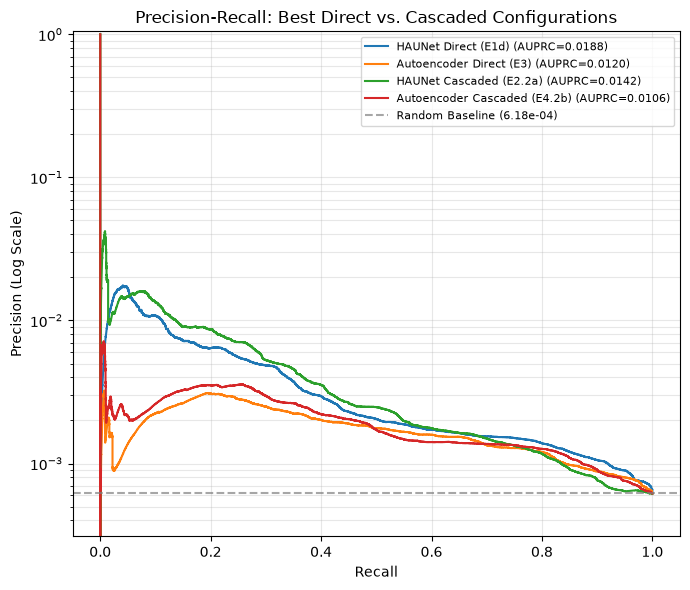

In [5]:
from pathlib import Path

# Identify project root (steps up if currently inside 'notebooks')
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

landsat_test_ids = load_split_ids(BUCKET, "landsat", "test", PREFIX, SPLITS_DIR)
landsat_test_ds = WildfireDataset(
    BUCKET, PREFIX, "landsat", split_ids=landsat_test_ids,
    dilate_target=False, heatmap_target=False,
    augment=False,
)

plot_pr_curves(
    [
        {"label": "HAUNet Direct (E1d)",          "preds_dir": PROJECT_ROOT / "logs/e1_haunet_direct_focal_dice_dilated_preds",                 "dataset": landsat_test_ds},
        {"label": "Autoencoder Direct (E3)",       "preds_dir": PROJECT_ROOT / "logs/e3_autoencoder_direct_focal_dice_preds",                    "dataset": landsat_test_ds},
        {"label": "HAUNet Cascaded (E2.2a)",       "preds_dir": PROJECT_ROOT / "logs/e2_haunet_cascaded_stage2_focal_dice_single_dilated_preds", "dataset": landsat_test_ds},
        {"label": "Autoencoder Cascaded (E4.2b)",  "preds_dir": PROJECT_ROOT / "logs/e4_autoencoder_cascaded_stage2_focal_dice_dilated_v2_preds",   "dataset": landsat_test_ds},
    ],
    title="Precision-Recall: Best Direct vs. Cascaded Configurations",
    out_path=PROJECT_ROOT / "deliverables/figures/pr_curve_all_best.png",
)

### Check ipsnr

In [60]:
import pandas as pd
from pathlib import Path

LOGS_DIR = Path("../logs")

configs = {
    "Full": "e1_haunet_direct_focal_dice_best_val_auprc_test_per_sample.csv",
    "Dilated": "e1_haunet_direct_focal_dice_dilated_best_val_auprc_test_per_sample.csv",
    "No Cov Pyramid": "e1_haunet_direct_focal_dice_no_cov_encoder_best_val_auprc_test_per_sample.csv",
    "No DEM": "e1_haunet_direct_focal_dice_no_dem_best_val_auprc_test_per_sample.csv",
    "No Land Cover": "e1_haunet_direct_focal_dice_no_landcover_best_val_auprc_test_per_sample.csv",
}

for name, fname in configs.items():
    path = LOGS_DIR / fname
    if not path.exists():
        print(f"[skip] {name}: {fname} not found")
        continue
    df = pd.read_csv(path)

    n_total = len(df)
    n_nonzero_ipsnr = df["ipsnr"].notna().sum()   # non-NaN = had a valid intersection
    n_nonzero_iou = (df["iou"] > 0).sum()          # samples with any true positive overlap at all

    print(f"\n--- {name} ---")
    print(f"  n_samples: {n_total}")
    print(f"  n_samples with valid (non-NaN) ipsnr: {n_nonzero_ipsnr}")
    print(f"  n_samples with iou > 0: {n_nonzero_iou}")
    print(f"  ipsnr mean (all valid): {df['ipsnr'].mean():.4f}")
    print(f"  ipsnr mean (only iou>0 samples): {df.loc[df['iou'] > 0, 'ipsnr'].mean():.4f}")
    print(f"  ipsnr median: {df['ipsnr'].median():.4f}")
    print(f"  ipsnr max: {df['ipsnr'].max():.4f}  (sample_id: "
          f"{df.loc[df['ipsnr'].idxmax(), 'sample_id'] if n_nonzero_ipsnr > 0 else 'N/A'})")
    print(f"  top 5 ipsnr values: {df['ipsnr'].nlargest(5).tolist()}")


--- Full ---
  n_samples: 121
  n_samples with valid (non-NaN) ipsnr: 121
  n_samples with iou > 0: 2
  ipsnr mean (all valid): 0.3618
  ipsnr mean (only iou>0 samples): 1.9527
  ipsnr median: 0.0442
  ipsnr max: 4.2790  (sample_id: LC08_L1TP_008052_20200813_20200813_01_RT_intersection_p00394)
  top 5 ipsnr values: [4.279021, 3.692351, 3.600191, 3.150324, 2.388698]

--- Dilated ---
  n_samples: 121
  n_samples with valid (non-NaN) ipsnr: 121
  n_samples with iou > 0: 5
  ipsnr mean (all valid): 0.3997
  ipsnr mean (only iou>0 samples): 2.7408
  ipsnr median: 0.0062
  ipsnr max: 4.6248  (sample_id: LC08_L1TP_033042_20200812_20200812_01_RT_intersection_p00174)
  top 5 ipsnr values: [4.624831, 4.547169, 4.480926, 4.271442, 4.258946]

--- No Cov Pyramid ---
  n_samples: 121
  n_samples with valid (non-NaN) ipsnr: 121
  n_samples with iou > 0: 4
  ipsnr mean (all valid): 0.4840
  ipsnr mean (only iou>0 samples): 3.2050
  ipsnr median: 0.0381
  ipsnr max: 5.2545  (sample_id: LC08_L1TP_22008

In [ ]:
viirs_train_ids = load_split_ids("wildfire-irp-data-th25", "viirs", "train",
                                  cfg["data"]["output_prefix"], cfg["data"].get("splits_dir", "splits"))
viirs_val_ids = load_split_ids("wildfire-irp-data-th25", "viirs", "val",
                                cfg["data"]["output_prefix"], cfg["data"].get("splits_dir", "splits"))
viirs_test_ids = load_split_ids("wildfire-irp-data-th25", "viirs", "test",
                                 cfg["data"]["output_prefix"], cfg["data"].get("splits_dir", "splits"))
print(f"VIIRS train/val/test: {len(viirs_train_ids)}/{len(viirs_val_ids)}/{len(viirs_test_ids)}")

[load_split_ids] Loaded 12504 IDs for viirs/train
[load_split_ids] Loaded 1563 IDs for viirs/val
[load_split_ids] Loaded 1564 IDs for viirs/test
VIIRS train/val/test: 12504/1563/1564


In [1]:
import sys, random, json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import yaml
import matplotlib.pyplot as plt

sys.path.append("../src")
from data.wildfire_dataset import WildfireDataset, load_split_ids
from utils.postprocess import postprocess_prediction
from models.autoencoder import make_model as make_autoencoder_model
from models.haunet import make_model as make_haunet_model

LOGS_DIR = Path("../logs")
FIG_DIR = Path("../deliverables/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# ------------------------------------------------------------------
# Core loader: builds model, loads checkpoint, runs inference on a
# chosen batch of samples (random or by explicit sample_id).
# ------------------------------------------------------------------
def load_model_and_batch(config_path, checkpoint_path, split="test",
                          n_samples=4, seed=42, sample_ids=None, load_undilated_target=False):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    with open(config_path) as f:
        cfg = yaml.safe_load(f)

    branch = cfg["experiment"]["branch"]
    bucket_name = cfg["data"]["bucket_name"]
    prefix = cfg["data"]["output_prefix"]
    splits_dir = cfg["data"].get("splits_dir", "splits")

    ids = load_split_ids(bucket_name, branch, split, prefix, splits_dir)
    ds = WildfireDataset(
        bucket_name, prefix, branch, split_ids=ids,
        goes_mean=cfg["data"].get("goes_mean"),
        goes_std=cfg["data"].get("goes_std"),
        use_stage1_pred=cfg["data"].get("use_stage1_pred", False),
        stage1_pred_key=cfg["data"].get("stage1_pred_key", "stage1_pred"),
        binarize_target=cfg["data"].get("binarize_target"),   # <-- add this
        dilate_target=cfg["data"].get("dilate_target", False),  # <-- and this, since it was also missing
        dilation_kernel_size=cfg["data"].get("dilation_kernel_size"),  # <-- and this, for correctness
    )

    if sample_ids:
        ds_id_to_idx = {m["id"]: i for i, m in enumerate(ds.samples)}
        chosen_idx = [ds_id_to_idx[sid] for sid in sample_ids if sid in ds_id_to_idx]
        if not chosen_idx:
            raise ValueError(f"None of {sample_ids} found in split '{split}'.")
    else:
        n = min(n_samples, len(ds))
        chosen_idx = random.sample(range(len(ds)), n)

    samples = [ds[i] for i in chosen_idx]
    batch = torch.utils.data.dataloader.default_collate(samples)
    sample_ids_out = batch["sample_id"]

    undilated_target = None
    if load_undilated_target and cfg["data"].get("dilate_target", False):
        ds_raw = WildfireDataset(
            bucket_name, prefix, branch, split_ids=ids,
            goes_mean=cfg["data"].get("goes_mean"), goes_std=cfg["data"].get("goes_std"),
            use_stage1_pred=cfg["data"].get("use_stage1_pred", False),
            stage1_pred_key=cfg["data"].get("stage1_pred_key", "stage1_pred"),
            dilate_target=False,
        )
        # Match by sample_id, not by chosen_idx position — ds_raw is a
        # separate dataset instance and is not guaranteed to share ds's
        # internal ordering, even with the same split_ids.
        raw_id_to_idx = {ds_raw[i]["sample_id"]: i for i in range(len(ds_raw))}
        missing = [sid for sid in sample_ids_out if sid not in raw_id_to_idx]
        if missing:
            raise ValueError(f"Sample ids missing from undilated dataset: {missing}")
        raw_samples = [ds_raw[raw_id_to_idx[sid]] for sid in sample_ids_out]
        undilated_target = torch.utils.data.dataloader.default_collate(raw_samples)["target"]
        # Sanity check: confirm alignment before trusting downstream plots.
        assert [s["sample_id"] for s in raw_samples] == list(sample_ids_out), \
            "Undilated target sample_ids do not match dilated batch sample_ids."

    model_type = cfg.get("model", {}).get("name", "").lower()
    exp_name = cfg.get("experiment", {}).get("name", "").lower()
    is_autoencoder = "autoencoder" in model_type or "autoencoder" in exp_name
    make_fn = make_autoencoder_model if is_autoencoder else make_haunet_model

    model = make_fn(
        goes_channels=cfg["data"]["goes_channels"],
        cov_channels=cfg["data"]["cov_channels"],
        stage1_channels=cfg["data"].get("stage1_channels", 0),
    ).to(DEVICE)

    ckpt = torch.load(checkpoint_path, map_location=DEVICE)
    state_dict = ckpt.get("model", ckpt.get("state_dict", ckpt))
    model.load_state_dict(state_dict)
    model.eval()

    inp = batch["input"].to(DEVICE)
    target = batch["target"].to(DEVICE)
    goes = batch["goes"]
    cov = batch["covariates"]

    with torch.no_grad():
        logits = model(inp)
        if logits.shape[-2:] != target.shape[-2:]:
            logits = F.adaptive_avg_pool2d(logits, target.shape[-2:])
        probs = torch.sigmoid(logits)
        pp_mask = postprocess_prediction(probs, method="percentile", percentile=99.5)

    return {
        "goes": goes, "cov": cov, "target": target, "probs": probs,
        "pp_mask": pp_mask, "sample_ids": sample_ids_out,
        "use_stage1_pred": cfg["data"].get("use_stage1_pred", False),
        "stage1_pred_np": (inp[:, cfg["data"]["goes_channels"]:cfg["data"]["goes_channels"]+1].cpu().numpy()
                            if cfg["data"].get("use_stage1_pred", False) else None),
        "undilated_target": undilated_target
    }

# ------------------------------------------------------------------
# Figure 2: per-experiment result panel — target / raw probability /
# Otsu-binarized mask / difference map. Reused for every experiment
# figure and for the failure-case figure.
# ------------------------------------------------------------------
def plot_result_panel(batch_data, title_prefix="", out=None, row_labels=None):
    target = batch_data["target"]
    probs = batch_data["probs"]
    pp_mask = batch_data["pp_mask"]
    n = target.shape[0]

    has_undilated = batch_data.get("undilated_target") is not None
    col_titles = (["Undilated target", "True target (dilated)"] if has_undilated else ["True target"]) + \
                 ["Predicted P(fire)", "Post-processed mask", "Difference (Pred - Target)"]
    n_cols = len(col_titles)
    fig, axes = plt.subplots(n, n_cols, figsize=(3.4 * n_cols, 3.2 * n))
    if n == 1:
        axes = axes[np.newaxis, :]

    for row in range(n):
        t = target[row, 0].cpu().numpy()
        p = probs[row, 0].cpu().numpy()
        pp = pp_mask[row, 0].cpu().numpy()
        d = p - t

        panels, cmaps, clims = [], [], []
        if has_undilated:
            panels.append(batch_data["undilated_target"][row, 0].cpu().numpy())
            cmaps.append("hot"); clims.append((0, 1))
        panels += [t, p, pp, d]
        cmaps += ["hot", "hot", "gray", "coolwarm"]
        clims += [(0, 1), (0, 1), (0, 1), (-1, 1)]

        for col in range(n_cols):  # was range(4) — bug: silently dropped the last column
            ax = axes[row, col]
            im = ax.imshow(panels[col], cmap=cmaps[col], vmin=clims[col][0], vmax=clims[col][1])
            if row == 0:
                ax.set_title(col_titles[col], fontsize=11)
            ax.set_xticks([]); ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        label = row_labels[row] if row_labels else f"{title_prefix}"
        axes[row, 0].set_ylabel(label, fontsize=8, rotation=90, labelpad=8)

    plt.tight_layout()
    if out:
        plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()


# ------------------------------------------------------------------
# Figure 3: cascade flow — GOES -> Stage 1 pred -> Stage 2 pred ->
# Landsat target, for one Stage-2 experiment whose input is Stage 1's
# output. Shows the pipeline concretely in one figure.
# ------------------------------------------------------------------
def plot_cascade_flow(stage2_batch_data, title_prefix="", out=None, row_labels=None):
    target = stage2_batch_data["target"]
    probs = stage2_batch_data["probs"]
    stage1_pred_np = stage2_batch_data["stage1_pred_np"]
    sample_ids = stage2_batch_data["sample_ids"]
    n = target.shape[0]

    if stage1_pred_np is None:
        raise ValueError("This batch wasn't built with use_stage1_pred=True in its config.")

    col_titles = ["Stage 1 P(fire) input", "Stage 2 Predicted P(fire)", "Landsat target"]
    fig, axes = plt.subplots(n, 3, figsize=(3.4 * 3, 3.2 * n))
    if n == 1:
        axes = axes[np.newaxis, :]

    for row in range(n):
        panels = [stage1_pred_np[row, 0], probs[row, 0].cpu().numpy(), target[row, 0].cpu().numpy()]
        for col in range(3):
            ax = axes[row, col]
            im = ax.imshow(panels[col], cmap="hot", vmin=0, vmax=1)
            if row == 0:
                ax.set_title(col_titles[col], fontsize=11)
            ax.set_xticks([]); ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        label = row_labels[row] if row_labels else f"{title_prefix}"
        axes[row, 0].set_ylabel(label, fontsize=8, rotation=90, labelpad=8)

    plt.tight_layout()
    if out:
        plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()


def plot_result_panel_viirs(batch_data, title_prefix="", out=None):
    target = batch_data["target"]
    probs = batch_data["probs"]
    n = target.shape[0]
    col_titles = ["True target", "Predicted P(fire)", "Difference (Pred - Target)"]
    fig, axes = plt.subplots(n, 3, figsize=(3.4 * 3, 3.2 * n))
    if n == 1:
        axes = axes[np.newaxis, :]
    for row in range(n):
        t = target[row, 0].cpu().numpy()
        p = probs[row, 0].cpu().numpy()
        d = p - t
        panels, cmaps, clims = [t, p, d], ["hot", "hot", "coolwarm"], [(0,1),(0,1),(-1,1)]
        for col in range(3):
            ax = axes[row, col]
            im = ax.imshow(panels[col], cmap=cmaps[col], vmin=clims[col][0], vmax=clims[col][1])
            if row == 0: ax.set_title(col_titles[col], fontsize=11)
            ax.set_xticks([]); ax.set_yticks([])
            for spine in ax.spines.values(): spine.set_visible(False)
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        axes[row, 0].set_ylabel(title_prefix, fontsize=8, rotation=90, labelpad=8)
    plt.tight_layout()
    if out: plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()

# ------------------------------------------------------------------
# Helper: pull worst-N sample_ids by a metric column from a per-sample
# CSV, for the failure-case figure.
# ------------------------------------------------------------------
def worst_samples(csv_path, metric_col="pp_iou", n=2, exclude_nan=True):
    df = pd.read_csv(csv_path)
    if exclude_nan:
        df = df.dropna(subset=[metric_col])
    return df.nsmallest(n, metric_col)["sample_id"].tolist()

In [2]:
import sys, random, json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import yaml
import matplotlib.pyplot as plt

sys.path.append("../src")
from data.wildfire_dataset import WildfireDataset, load_split_ids
from utils.postprocess import postprocess_prediction
from models.autoencoder import make_model as make_autoencoder_model
from models.haunet import make_model as make_haunet_model

LOGS_DIR = Path("../logs")
FIG_DIR = Path("../deliverables/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# ------------------------------------------------------------------
# Core loader: builds model, loads checkpoint, runs inference on a
# chosen batch of samples (random or by explicit sample_id).
# ------------------------------------------------------------------
def load_model_and_batch(config_path, checkpoint_path, split="test",
                          n_samples=4, seed=42, sample_ids=None, load_undilated_target=False):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    with open(config_path) as f:
        cfg = yaml.safe_load(f)

    branch = cfg["experiment"]["branch"]
    bucket_name = cfg["data"]["bucket_name"]
    prefix = cfg["data"]["output_prefix"]
    splits_dir = cfg["data"].get("splits_dir", "splits")

    ids = load_split_ids(bucket_name, branch, split, prefix, splits_dir)
    ds = WildfireDataset(
        bucket_name, prefix, branch, split_ids=ids,
        goes_mean=cfg["data"].get("goes_mean"),
        goes_std=cfg["data"].get("goes_std"),
        use_stage1_pred=cfg["data"].get("use_stage1_pred", False),
        stage1_pred_key=cfg["data"].get("stage1_pred_key", "stage1_pred"),
        binarize_target=cfg["data"].get("binarize_target"),   # <-- add this
        dilate_target=cfg["data"].get("dilate_target", False),  # <-- and this, since it was also missing
        dilation_kernel_size=cfg["data"].get("dilation_kernel_size"),  # <-- and this, for correctness
    )

    if sample_ids:
        ds_id_to_idx = {m["id"]: i for i, m in enumerate(ds.samples)}
        chosen_idx = [ds_id_to_idx[sid] for sid in sample_ids if sid in ds_id_to_idx]
        if not chosen_idx:
            raise ValueError(f"None of {sample_ids} found in split '{split}'.")
    else:
        n = min(n_samples, len(ds))
        chosen_idx = random.sample(range(len(ds)), n)

    samples = [ds[i] for i in chosen_idx]
    batch = torch.utils.data.dataloader.default_collate(samples)
    sample_ids_out = batch["sample_id"]

    undilated_target = None
    if load_undilated_target and cfg["data"].get("dilate_target", False):
        ds_raw = WildfireDataset(
            bucket_name, prefix, branch, split_ids=ids,
            goes_mean=cfg["data"].get("goes_mean"), goes_std=cfg["data"].get("goes_std"),
            use_stage1_pred=cfg["data"].get("use_stage1_pred", False),
            stage1_pred_key=cfg["data"].get("stage1_pred_key", "stage1_pred"),
            dilate_target=False,
        )
        # Match by sample_id, not by chosen_idx position — ds_raw is a
        # separate dataset instance and is not guaranteed to share ds's
        # internal ordering, even with the same split_ids.
        raw_id_to_idx = {ds_raw[i]["sample_id"]: i for i in range(len(ds_raw))}
        missing = [sid for sid in sample_ids_out if sid not in raw_id_to_idx]
        if missing:
            raise ValueError(f"Sample ids missing from undilated dataset: {missing}")
        raw_samples = [ds_raw[raw_id_to_idx[sid]] for sid in sample_ids_out]
        undilated_target = torch.utils.data.dataloader.default_collate(raw_samples)["target"]
        # Sanity check: confirm alignment before trusting downstream plots.
        assert [s["sample_id"] for s in raw_samples] == list(sample_ids_out), \
            "Undilated target sample_ids do not match dilated batch sample_ids."

    model_type = cfg.get("model", {}).get("name", "").lower()
    exp_name = cfg.get("experiment", {}).get("name", "").lower()
    is_autoencoder = "autoencoder" in model_type or "autoencoder" in exp_name
    make_fn = make_autoencoder_model if is_autoencoder else make_haunet_model

    model = make_fn(
        goes_channels=cfg["data"]["goes_channels"],
        cov_channels=cfg["data"]["cov_channels"],
        stage1_channels=cfg["data"].get("stage1_channels", 0),
    ).to(DEVICE)

    ckpt = torch.load(checkpoint_path, map_location=DEVICE)
    state_dict = ckpt.get("model", ckpt.get("state_dict", ckpt))
    model.load_state_dict(state_dict)
    model.eval()

    inp = batch["input"].to(DEVICE)
    target = batch["target"].to(DEVICE)
    goes = batch["goes"]
    cov = batch["covariates"]

    with torch.no_grad():
        logits = model(inp)
        if logits.shape[-2:] != target.shape[-2:]:
            logits = F.adaptive_avg_pool2d(logits, target.shape[-2:])
        probs = torch.sigmoid(logits)
        pp_mask = postprocess_prediction(probs, method="percentile", percentile=99.5)

    return {
        "goes": goes, "cov": cov, "target": target, "probs": probs,
        "pp_mask": pp_mask, "sample_ids": sample_ids_out,
        "use_stage1_pred": cfg["data"].get("use_stage1_pred", False),
        "stage1_pred_np": (inp[:, cfg["data"]["goes_channels"]:cfg["data"]["goes_channels"]+1].cpu().numpy()
                            if cfg["data"].get("use_stage1_pred", False) else None),
        "undilated_target": undilated_target
    }

# ------------------------------------------------------------------
# Figure 2: per-experiment result panel — target / raw probability /
# Otsu-binarized mask / difference map. Reused for every experiment
# figure and for the failure-case figure.
# ------------------------------------------------------------------
def plot_result_panel(batch_data, title_prefix="", out=None, row_labels=None):
    target = batch_data["target"]
    probs = batch_data["probs"]
    pp_mask = batch_data["pp_mask"]
    n = target.shape[0]

    has_undilated = batch_data.get("undilated_target") is not None
    col_titles = (["Undilated target", "True target (dilated)"] if has_undilated else ["True target"]) + \
                 ["Predicted P(fire)", "Post-processed mask", "Difference (Pred - Target)"]
    n_cols = len(col_titles)
    fig, axes = plt.subplots(n, n_cols, figsize=(3.4 * n_cols, 3.2 * n))
    if n == 1:
        axes = axes[np.newaxis, :]

    for row in range(n):
        t = target[row, 0].cpu().numpy()
        p = probs[row, 0].cpu().numpy()
        pp = pp_mask[row, 0].cpu().numpy()
        d = p - t

        panels, cmaps, clims = [], [], []
        if has_undilated:
            panels.append(batch_data["undilated_target"][row, 0].cpu().numpy())
            cmaps.append("hot"); clims.append((0, 1))
        panels += [t, p, pp, d]
        cmaps += ["hot", "hot", "gray", "coolwarm"]
        clims += [(0, 1), (0, 1), (0, 1), (-1, 1)]

        for col in range(n_cols):  # was range(4) — bug: silently dropped the last column
            ax = axes[row, col]
            im = ax.imshow(panels[col], cmap=cmaps[col], vmin=clims[col][0], vmax=clims[col][1])
            if row == 0:
                ax.set_title(col_titles[col], fontsize=11)
            ax.set_xticks([]); ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        label = row_labels[row] if row_labels else f"{title_prefix}"
        axes[row, 0].set_ylabel(label, fontsize=8, rotation=90, labelpad=8)

    plt.tight_layout()
    if out:
        plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()


# ------------------------------------------------------------------
# Figure 3: cascade flow — GOES -> Stage 1 pred -> Stage 2 pred ->
# Landsat target, for one Stage-2 experiment whose input is Stage 1's
# output. Shows the pipeline concretely in one figure.
# ------------------------------------------------------------------
def to_viirs_native(upsampled_256, target_size=20):
    # upsampled_256: (H, W) numpy array, already interpolated up from 20x20
    t = torch.from_numpy(upsampled_256)[None, None].float()
    native = F.adaptive_avg_pool2d(t, (target_size, target_size))
    return native[0, 0].numpy()

def plot_cascade_flow(stage2_batch_data, title_prefix="", out=None, row_labels=None):
    target = stage2_batch_data["target"]
    probs = stage2_batch_data["probs"]
    stage1_pred_np = stage2_batch_data["stage1_pred_np"]
    sample_ids = stage2_batch_data["sample_ids"]
    n = target.shape[0]

    if stage1_pred_np is None:
        raise ValueError("This batch wasn't built with use_stage1_pred=True in its config.")

    col_titles = ["Stage 1 P(fire) input", "Stage 2 Predicted P(fire)", "Landsat target"]
    fig, axes = plt.subplots(n, 3, figsize=(3.4 * 3, 3.2 * n))
    if n == 1:
        axes = axes[np.newaxis, :]

    for row in range(n):
        panels = [
            to_viirs_native(stage1_pred_np[row, 0]),
            probs[row, 0].cpu().numpy(),
            target[row, 0].cpu().numpy()
        ]
        for col in range(3):
            ax = axes[row, col]
            im = ax.imshow(panels[col], cmap="hot", vmin=0, vmax=1,
                interpolation="nearest" if col == 0 else "bilinear")
            if row == 0:
                ax.set_title(col_titles[col], fontsize=11)
            ax.set_xticks([]); ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        label = row_labels[row] if row_labels else f"{title_prefix}"
        axes[row, 0].set_ylabel(label, fontsize=8, rotation=90, labelpad=8)

    plt.tight_layout()
    if out:
        plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()


def plot_result_panel_viirs(batch_data, title_prefix="", out=None):
    target = batch_data["target"]
    probs = batch_data["probs"]
    n = target.shape[0]
    col_titles = ["True target", "Predicted P(fire)", "Difference (Pred - Target)"]
    fig, axes = plt.subplots(n, 3, figsize=(3.4 * 3, 3.2 * n))
    if n == 1:
        axes = axes[np.newaxis, :]
    for row in range(n):
        t = target[row, 0].cpu().numpy()
        p = probs[row, 0].cpu().numpy()
        d = p - t
        panels, cmaps, clims = [t, p, d], ["hot", "hot", "coolwarm"], [(0,1),(0,1),(-1,1)]
        for col in range(3):
            ax = axes[row, col]
            im = ax.imshow(panels[col], cmap=cmaps[col], vmin=clims[col][0], vmax=clims[col][1])
            if row == 0: ax.set_title(col_titles[col], fontsize=11)
            ax.set_xticks([]); ax.set_yticks([])
            for spine in ax.spines.values(): spine.set_visible(False)
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        axes[row, 0].set_ylabel(title_prefix, fontsize=8, rotation=90, labelpad=8)
    plt.tight_layout()
    if out: plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()

# ------------------------------------------------------------------
# Helper: pull worst-N sample_ids by a metric column from a per-sample
# CSV, for the failure-case figure.
# ------------------------------------------------------------------
def worst_samples(csv_path, metric_col="pp_iou", n=2, exclude_nan=True):
    df = pd.read_csv(csv_path)
    if exclude_nan:
        df = df.dropna(subset=[metric_col])
    return df.nsmallest(n, metric_col)["sample_id"].tolist()

In [3]:
def load_data_reference(config_path, sample_ids=None, split="test", n_samples=3, seed=42,
                          dilate_target=True, dilation_kernel_size=7, binarize_target=True):
    """
    Loads raw input data (GOES, covariates, target) for a set of samples,
    with NO model involved — purely for a "what does the data look like" figure.
    Explicit dilate_target/dilation_kernel_size/binarize_target args, since relying
    on YAML defaults has been unreliable this session.
    """
    with open(config_path) as f:
        cfg = yaml.safe_load(f)

    branch = cfg["experiment"]["branch"]
    bucket_name = cfg["data"]["bucket_name"]
    prefix = cfg["data"]["output_prefix"]
    splits_dir = cfg["data"].get("splits_dir", "splits")

    ids = load_split_ids(bucket_name, branch, split, prefix, splits_dir)
    landsat_ds = WildfireDataset(
        bucket_name, prefix, branch, split_ids=ids,
        goes_mean=cfg["data"].get("goes_mean"), goes_std=cfg["data"].get("goes_std"),
        dem_mean=cfg["data"].get("dem_mean"), dem_std=cfg["data"].get("dem_std"),
        binarize_target=binarize_target,
        dilate_target=dilate_target,
        dilation_kernel_size=dilation_kernel_size,
    )

    if sample_ids:
        ds_id_to_idx = {m["id"]: i for i, m in enumerate(landsat_ds.samples)}
        chosen_ids = [sid for sid in sample_ids if sid in ds_id_to_idx]
        if not chosen_ids:
            raise ValueError(f"None of {sample_ids} found in split '{split}'.")
    else:
        random.seed(seed)
        chosen_ids = random.sample([m["id"] for m in landsat_ds.samples], n_samples)

    id_to_manifest = {m["id"]: m for m in landsat_ds.samples}

    goes_list, cov_list, undilated_list, dilated_list, ids_out = [], [], [], [], []

    for sid in chosen_ids:
        paths = id_to_manifest[sid]["paths"]

        target_raw = landsat_ds._read_gcs_raster(paths["target"])
        goes = landsat_ds._read_gcs_raster(paths["goes_input"])
        cov = landsat_ds._read_gcs_raster(paths["covariates"])

        # Snap raw cov to a consistent size for display (raw exports vary by ±1px)
        if cov.shape[-2:] != landsat_ds.cov_size:
            cov = F.interpolate(cov.unsqueeze(0), size=landsat_ds.cov_size,
                                 mode="bilinear", align_corners=False).squeeze(0)

        goes_norm = (goes - landsat_ds.goes_mean) / landsat_ds.goes_std
        goes_native = F.interpolate(goes_norm.unsqueeze(0), size=landsat_ds.goes_size,
                                     mode="bilinear", align_corners=False).squeeze(0)
        goes_up = F.interpolate(goes_native.unsqueeze(0), size=landsat_ds.cov_size,
                                 mode="bilinear", align_corners=False).squeeze(0)

        dem = cov[0:1] / 1000.0
        dem_norm = (dem - landsat_ds.dem_mean) / landsat_ds.dem_std
        lc_onehot = landsat_ds._onehot_landcover(cov[1:2])
        cov_processed = torch.cat([dem_norm, lc_onehot], dim=0)
        if cov_processed.shape[-2:] != landsat_ds.cov_size:
            cov_processed = F.interpolate(cov_processed.unsqueeze(0), size=landsat_ds.cov_size,
                                           mode="bilinear", align_corners=False).squeeze(0)

        target_bin = (target_raw > 0).float() if binarize_target else target_raw
        if dilate_target:
            padding = dilation_kernel_size // 2
            dilated_raw = F.max_pool2d(target_bin.unsqueeze(0), kernel_size=dilation_kernel_size,
                                        stride=1, padding=padding).squeeze(0)
            dilated_raw = (dilated_raw > 0).float()
        else:
            dilated_raw = target_bin

        undilated_256 = F.interpolate(target_bin.unsqueeze(0), size=(256, 256), mode="nearest").squeeze(0)
        dilated_256 = F.interpolate(dilated_raw.unsqueeze(0), size=(256, 256), mode="nearest").squeeze(0)

        goes_list.append(goes_native)
        cov_list.append(cov)
        undilated_list.append(undilated_256)
        dilated_list.append(dilated_256)
        ids_out.append(sid)

    return {
        "goes": torch.stack(goes_list),
        "cov": torch.stack(cov_list),
        "undilated_target": torch.stack(undilated_list),
        "dilated_target": torch.stack(dilated_list),
        "sample_ids": ids_out,
    }

def plot_input_reference_no_target(data, out=None, row_labels=None):
    goes = data["goes"]
    cov = data["cov"]
    n = goes.shape[0]

    titles = ["GOES C07", "GOES C14", "GOES TFI", "DEM", "Land cover"]
    cmaps = ["inferno", "inferno", "inferno", "terrain", "tab20"]
    n_cols = len(titles)

    fig, axes = plt.subplots(n, n_cols, figsize=(3.2 * n_cols, 3 * n))
    if n == 1:
        axes = axes[np.newaxis, :]

    for row in range(n):
        panels = [goes[row, 0].numpy(), goes[row, 1].numpy(), goes[row, 2].numpy(),
                  cov[row, 0].numpy(), cov[row, 1].numpy()]
        for col in range(n_cols):
            ax = axes[row, col]
            im = ax.imshow(panels[col], cmap=cmaps[col], interpolation="nearest")
            if row == 0:
                ax.set_title(titles[col], fontsize=11)
            ax.set_xticks([]); ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        label = row_labels[row] if row_labels else data["sample_ids"][row]
        axes[row, 0].set_ylabel(label, fontsize=8, rotation=90, labelpad=8)

    plt.tight_layout()
    if out:
        plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()

Found 62 samples with > 20 active target pixels (out of 121 scanned).
Selected IDs (id, active_pixel_count):
  LC08_L1TP_008047_20200813_20200813_01_RT_intersection_p00344: 33
  LC08_L1TP_033042_20200812_20200812_01_RT_intersection_p00174: 45
  LC08_L1TP_229070_20200809_20200809_01_RT_intersection_p00482: 49
[load_split_ids] Loaded 121 IDs for landsat/test
[WildfireDataset/landsat] Split filter: 121/121 samples in provided split.
[WildfireDataset/landsat] 121 usable pairs.
[WildfireDataset/landsat] sizes: target=(256, 256), cov=(256, 256), goes=(4, 4)


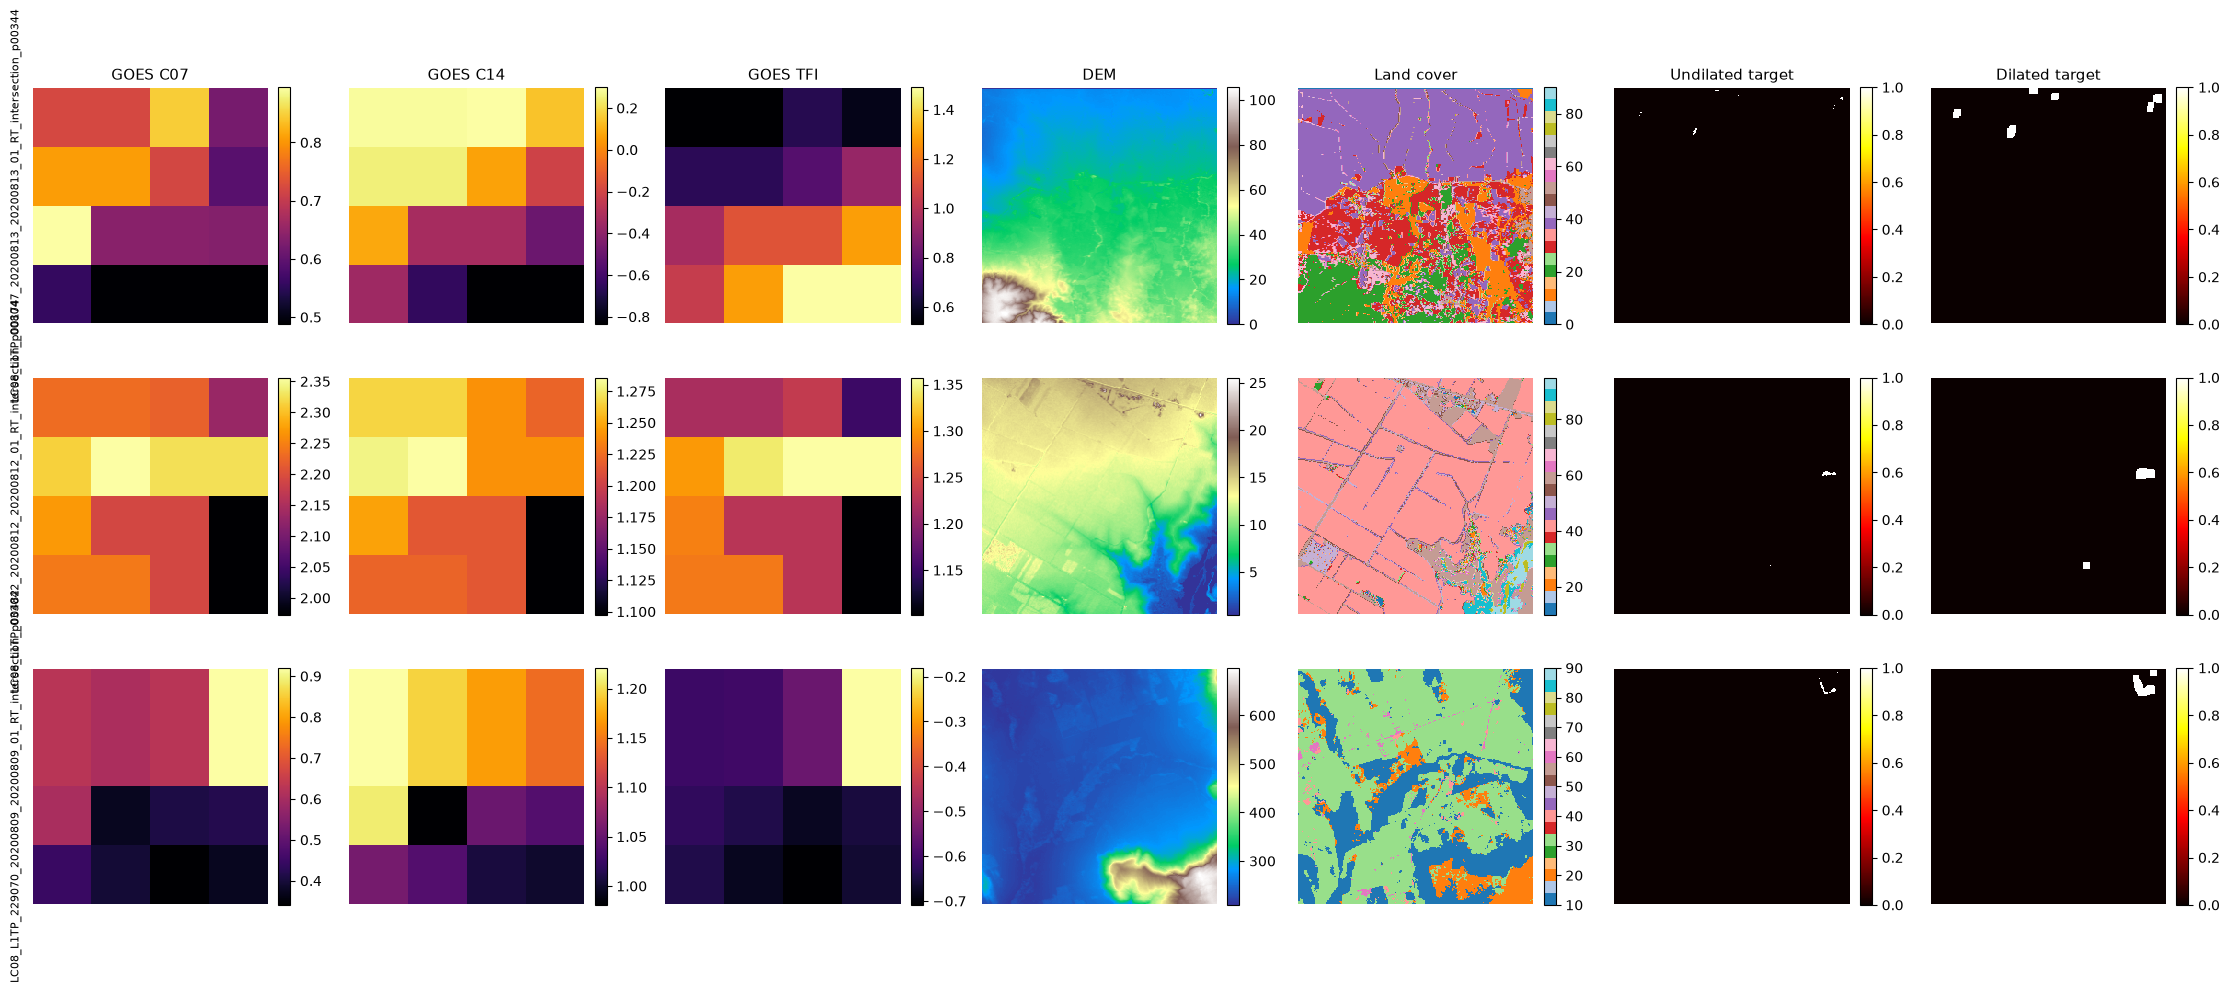

In [182]:
current_ids_ref = find_ids_with_min_fire_pixels(ds, min_pixels=20, n_ids=3, seed=42)

ref_data = load_data_reference(
    "../experiments/e1_haunet_direct.YAML",
    sample_ids=current_ids_ref,
    dilate_target=True, dilation_kernel_size=7, binarize_target=True,
)
plot_input_reference(ref_data, out=FIG_DIR / "input_reference.png")

In [4]:
def load_model_from_config(config_path, checkpoint_path):
    with open(config_path) as f:
        cfg = yaml.safe_load(f)

    model_type = cfg.get("model", {}).get("name", "").lower()
    exp_name = cfg.get("experiment", {}).get("name", "").lower()
    is_autoencoder = "autoencoder" in model_type or "autoencoder" in exp_name
    make_fn = make_autoencoder_model if is_autoencoder else make_haunet_model

    model = make_fn(
        goes_channels=cfg["data"]["goes_channels"],
        cov_channels=cfg["data"]["cov_channels"],
        stage1_channels=cfg["data"].get("stage1_channels", 0),
    ).to(DEVICE)

    ckpt = torch.load(checkpoint_path, map_location=DEVICE)
    state_dict = ckpt.get("model", ckpt.get("state_dict", ckpt))
    try:
        model.load_state_dict(state_dict)
    except RuntimeError as e:
        raise RuntimeError(
            f"Checkpoint at {checkpoint_path} does not match architecture "
            f"'{'autoencoder' if is_autoencoder else 'haunet'}' inferred from {config_path}. "
            f"Likely a config/checkpoint mismatch — verify paths."
        ) from e
    model.eval()
    return model, cfg


def run_cascade_live(sample_ids, stage1_cfg_path, stage1_ckpt_path,
                      stage2_cfg_path, stage2_ckpt_path, landsat_ds,
                      dilate_target=True, dilation_kernel_size=7):
    """
    Runs the true cascade pipeline live on the given Landsat sample_ids:
    Landsat rasters -> Stage 1 forward pass (native VIIRS-res output) -> upsample -> Stage 2 forward pass.

    landsat_ds: a WildfireDataset built from the Stage 2 (landsat) config — used only
                for its raster-reading/normalization helper methods and to look up
                manifests by sample_id. Its .cov_size/.goes_size are reused for both stages.
    dilate_target / dilation_kernel_size: explicit dilation settings for the target,
                applied at raw resolution before downsampling — set to match whichever
                Stage 2 checkpoint's training config you're evaluating.
    """
    stage1_model, stage1_cfg = load_model_from_config(stage1_cfg_path, stage1_ckpt_path)
    stage2_model, stage2_cfg = load_model_from_config(stage2_cfg_path, stage2_ckpt_path)

    id_to_manifest = {m["id"]: m for m in landsat_ds.samples}
    missing = [sid for sid in sample_ids if sid not in id_to_manifest]
    if missing:
        raise ValueError(f"Sample ids missing from landsat dataset manifest: {missing}")

    results = {"sample_ids": [], "target": [], "undilated_target": [],
               "stage1_probs": [], "stage2_probs": [], "stage2_pp_mask": [], "goes_tfi": []}

    for sid in sample_ids:
        manifest = id_to_manifest[sid]
        paths = manifest["paths"]

        target_raw = landsat_ds._read_gcs_raster(paths["target"])
        goes = landsat_ds._read_gcs_raster(paths["goes_input"])
        cov = landsat_ds._read_gcs_raster(paths["covariates"])

        goes = (goes - landsat_ds.goes_mean) / landsat_ds.goes_std
        dem = cov[0:1] / 1000.0
        dem = (dem - landsat_ds.dem_mean) / landsat_ds.dem_std
        lc_onehot = landsat_ds._onehot_landcover(cov[1:2])
        cov = torch.cat([dem, lc_onehot], dim=0)

        goes_native = F.interpolate(goes.unsqueeze(0), size=landsat_ds.goes_size,
                                     mode="bilinear", align_corners=False).squeeze(0)
        goes_up = F.interpolate(goes_native.unsqueeze(0), size=landsat_ds.cov_size,
                                 mode="bilinear", align_corners=False).squeeze(0)
        if cov.shape[-2:] != landsat_ds.cov_size:
            cov = F.interpolate(cov.unsqueeze(0), size=landsat_ds.cov_size,
                                 mode="bilinear", align_corners=False).squeeze(0)

        # 1. Binarize raw target
        target_raw_bin = (target_raw > 0).float() if landsat_ds.binarize_target else target_raw

        # 2. Dilate AT RAW RESOLUTION
        if dilate_target:
            padding = dilation_kernel_size // 2
            dilated_raw = F.max_pool2d(
                target_raw_bin.unsqueeze(0),
                kernel_size=dilation_kernel_size,
                stride=1,
                padding=padding,
            ).squeeze(0)
            dilated_raw = (dilated_raw > 0).float()
        else:
            dilated_raw = target_raw_bin

        # 3. Downsample both targets to (256, 256) using nearest neighbor
        undilated_target = F.interpolate(target_raw_bin.unsqueeze(0), size=(256, 256), mode="nearest").squeeze(0)
        dilated_target = F.interpolate(dilated_raw.unsqueeze(0), size=(256, 256), mode="nearest").squeeze(0)

        # ---- Stage 1 forward: input = goes_up + cov ----
        stage1_input = torch.cat([goes_up, cov], dim=0).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            stage1_logits = stage1_model(stage1_input)   # model output res, e.g. (1,1,256,256)
            viirs_target_size = stage1_cfg["data"].get("target_size", (20, 20))
            if stage1_logits.shape[-2:] != tuple(viirs_target_size):
                stage1_logits_native = F.adaptive_avg_pool2d(stage1_logits, tuple(viirs_target_size))
            else:
                stage1_logits_native = stage1_logits
            stage1_probs_native = torch.sigmoid(stage1_logits_native)   # true native, e.g. (1,1,20,20)

        # ---- Stage 2 forward: input = goes_up + upsampled stage1 pred + cov ----
        stage1_pred_up = F.interpolate(stage1_probs_native, size=landsat_ds.cov_size,
                                        mode="bilinear", align_corners=False)
        stage2_input = torch.cat(
            [goes_up.unsqueeze(0).to(DEVICE), stage1_pred_up, cov.unsqueeze(0).to(DEVICE)], dim=1)
        with torch.no_grad():
            stage2_logits = stage2_model(stage2_input)
            if stage2_logits.shape[-2:] != (256, 256):
                stage2_logits = F.adaptive_avg_pool2d(stage2_logits, (256, 256))
            stage2_probs = torch.sigmoid(stage2_logits)
            stage2_pp = postprocess_prediction(stage2_probs, method="percentile", percentile=99.5)

        results["sample_ids"].append(sid)
        results["target"].append(dilated_target)
        results["undilated_target"].append(undilated_target)
        results["stage1_probs"].append(stage1_probs_native[0].cpu())   # genuinely native, e.g. (1,20,20)
        results["stage2_probs"].append(stage2_probs[0].cpu())
        results["stage2_pp_mask"].append(stage2_pp[0].cpu())
        results["goes_tfi"].append(goes_native[2].cpu())   # channel 2 = GOES TFI, native res

    return {
        "sample_ids": results["sample_ids"],
        "target": torch.stack(results["target"]),
        "undilated_target": torch.stack(results["undilated_target"]),
        "probs": torch.stack(results["stage2_probs"]),
        "pp_mask": torch.stack(results["stage2_pp_mask"]),
        "stage1_probs_native": results["stage1_probs"],   # kept as list, native res may vary
        "goes_tfi": results["goes_tfi"],                   # kept as list, native res may vary
        "use_stage1_pred": True,
    }

In [5]:
def plot_pipeline_panel(batch_data, stage2_ds=None, title_prefix="", out=None, row_labels=None):
    """
    Unified panel for direct or cascaded pipelines.
    batch_data: output of load_model_and_batch(...) or run_cascade_live(...)
    stage2_ds: only required as a guard for cascaded batches; not used for raster fetching
               anymore (stage1_probs_native comes from batch_data directly).
    """
    is_cascaded = batch_data.get("use_stage1_pred", False)
    if is_cascaded and stage2_ds is None:
        raise ValueError("stage2_ds is required for cascaded batches.")

    target = batch_data["target"]
    probs = batch_data["probs"]
    pp_mask = batch_data["pp_mask"]
    has_undilated = batch_data.get("undilated_target") is not None
    n = target.shape[0]

    stage1_native = batch_data.get("stage1_probs_native") if is_cascaded else None
    has_goes = "goes_tfi" in batch_data

    col_titles = []
    if has_goes:
        col_titles.append("GOES TFI (native)")
    col_titles += (["Undilated target", "Dilated target"] if has_undilated else ["Target"])
    if is_cascaded:
        h, w = stage1_native[0].shape[-2:]
        col_titles += [f"Stage 2 input: Stage 1 P(fire) (native {w}x{h})"]
        col_titles += ["Stage 2 P(fire) (raw)", "Stage 2 post-processed"]
    else:
        col_titles += ["Predicted P(fire) (raw)", "Post-processed mask"]
    col_titles += ["Difference (Pred - Target)"]
    n_cols = len(col_titles)

    fig, axes = plt.subplots(n, n_cols, figsize=(3.2 * n_cols, 3.1 * n))
    if n == 1:
        axes = axes[np.newaxis, :]

    for row in range(n):
        panels, cmaps, clims, interps = [], [], [], []

        if has_goes:
            goes_val = batch_data["goes_tfi"][row]
            goes_val = goes_val.cpu().numpy() if torch.is_tensor(goes_val) else goes_val
            panels.append(goes_val)
            cmaps.append("inferno"); clims.append((None, None)); interps.append("nearest")

        if has_undilated:
            panels.append(batch_data["undilated_target"][row, 0].cpu().numpy())
            cmaps.append("hot"); clims.append((0, 1)); interps.append("nearest")

        panels.append(target[row, 0].cpu().numpy())
        cmaps.append("hot"); clims.append((0, 1)); interps.append("nearest")

        if is_cascaded:
            panels.append(stage1_native[row][0].numpy() if torch.is_tensor(stage1_native[row]) else stage1_native[row][0])
            cmaps.append("hot"); clims.append((0, 1)); interps.append("nearest")

        p = probs[row, 0].cpu().numpy()
        pp = pp_mask[row, 0].cpu().numpy()
        t_eval = (batch_data["undilated_target"][row, 0].cpu().numpy()
                  if has_undilated else target[row, 0].cpu().numpy())

        panels.append(p); cmaps.append("hot"); clims.append((0, 1)); interps.append("bilinear")
        panels.append(pp); cmaps.append("gray"); clims.append((0, 1)); interps.append("bilinear")
        panels.append(pp - t_eval); cmaps.append("coolwarm"); clims.append((-1, 1)); interps.append("bilinear")

        for col in range(n_cols):
            ax = axes[row, col]
            im = ax.imshow(panels[col], cmap=cmaps[col], vmin=clims[col][0], vmax=clims[col][1],
                            interpolation=interps[col])
            if row == 0:
                ax.set_title(col_titles[col], fontsize=10)
            ax.set_xticks([]); ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        label = row_labels[row] if row_labels else title_prefix
        axes[row, 0].set_ylabel(label, fontsize=8, rotation=90, labelpad=8)

    plt.tight_layout()
    if out:
        plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()

In [6]:
import random

def find_ids_with_min_fire_pixels(landsat_ds, min_pixels=20, n_ids=3, seed=None, max_scan=None):
    candidates = []
    samples_to_scan = landsat_ds.samples if max_scan is None else landsat_ds.samples[:max_scan]

    for manifest in samples_to_scan:
        target = landsat_ds._read_gcs_raster(manifest["paths"]["target"])
        active_pixels = (target > 0).sum().item()
        if active_pixels > min_pixels:
            candidates.append((manifest["id"], active_pixels))

    print(f"Found {len(candidates)} samples with > {min_pixels} active target pixels "
          f"(out of {len(samples_to_scan)} scanned).")

    if not candidates:
        return []

    if seed is not None:
        random.seed(seed)
    chosen = random.sample(candidates, min(n_ids, len(candidates)))

    chosen_ids = [c[0] for c in chosen]
    print("Selected IDs (id, active_pixel_count):")
    for cid, count in chosen:
        print(f"  {cid}: {count}")

    return chosen_ids

In [7]:
with open("../experiments/e2_haunet_cascaded_stage2.YAML") as f:
    cfg = yaml.safe_load(f)

ids = load_split_ids(cfg["data"]["bucket_name"], cfg["experiment"]["branch"], "test",
                      cfg["data"]["output_prefix"], cfg["data"].get("splits_dir", "splits"))

ds = WildfireDataset(
    cfg["data"]["bucket_name"], cfg["data"]["output_prefix"], cfg["experiment"]["branch"],
    split_ids=ids,
    goes_mean=cfg["data"].get("goes_mean"), goes_std=cfg["data"].get("goes_std"),
    use_stage1_pred=cfg["data"].get("use_stage1_pred", False),
    stage1_pred_key=cfg["data"].get("stage1_pred_key", "stage1_pred"),
)

[load_split_ids] Loaded 121 IDs for landsat/test
[WildfireDataset/landsat] Split filter: 121/121 samples in provided split.
[WildfireDataset/landsat] 121 usable pairs.
[WildfireDataset/landsat] sizes: target=(256, 256), cov=(256, 256), goes=(4, 4)


In [8]:
from google.cloud import storage
import os

def download_checkpoint_if_missing(bucket_name, gcs_relative_path, local_path):
    """
    gcs_relative_path: path under the bucket, e.g.
        'processed_dataset_gcp/checkpoints/e2_haunet_cascaded_stage1_focal_dice/best_val_auprc.pt'
    local_path: where to save it locally, e.g.
        '../checkpoints/e2_haunet_cascaded_stage1_focal_dice/best_val_auprc.pt'
    """
    if os.path.exists(local_path):
        print(f"Already present: {local_path}")
        return local_path

    os.makedirs(os.path.dirname(local_path), exist_ok=True)
    bucket = storage.Client().bucket(bucket_name)
    blob = bucket.blob(gcs_relative_path)
    if not blob.exists():
        raise FileNotFoundError(f"Not found in bucket: gs://{bucket_name}/{gcs_relative_path}")
    print(f"Downloading gs://{bucket_name}/{gcs_relative_path} -> {local_path} ...")
    blob.download_to_filename(local_path)
    print("Done.")
    return local_path

In [9]:
bucket_name = cfg["data"]["bucket_name"]

download_checkpoint_if_missing(
    bucket_name,
    "processed_dataset_gcp/checkpoints/e2_haunet_cascaded_stage1_focal_dice/best_val_auprc.pt",
    "../checkpoints/e2_haunet_cascaded_stage1_focal_dice/best_val_auprc.pt",
)
download_checkpoint_if_missing(
    bucket_name,
    "processed_dataset_gcp/checkpoints/e2_haunet_cascaded_stage2_focal_dice_single_dilated/best_val_auprc.pt",
    "../checkpoints/e2_haunet_cascaded_stage2_focal_dice_single_dilated/best_val_auprc.pt",
)

download_checkpoint_if_missing(
    bucket_name,
    "processed_dataset_gcp/checkpoints/e4_autoencoder_cascaded_stage1_focal_dice/best_val_auprc.pt",
    "../checkpoints/e4_autoencoder_cascaded_stage1_focal_dice/best_val_auprc.pt",
)
download_checkpoint_if_missing(
    bucket_name,
    "processed_dataset_gcp/checkpoints/e4_autoencoder_cascaded_stage2_focal_dice_dilated/best_val_auprc.pt",
    "../checkpoints/e4_autoencoder_cascaded_stage2_focal_dice_dilated/best_val_auprc.pt",
)

download_checkpoint_if_missing(
    bucket_name,
    "processed_dataset_gcp/checkpoints/e1_haunet_direct_focal_dice_dilated/best_val_auprc.pt",
    "../checkpoints/e1_haunet_direct_focal_dice_dilated/best_val_auprc.pt",
)

download_checkpoint_if_missing(
    bucket_name,
    "processed_dataset_gcp/checkpoints/e3_autoencoder_direct_focal_dice_dilated/best_val_auprc.pt",
    "../checkpoints/e3_autoencoder_direct_focal_dice_dilated/best_val_auprc.pt",
)

Done.
Done.
Done.
Done.
Done.
Done.


'../checkpoints/e3_autoencoder_direct_focal_dice_dilated/best_val_auprc.pt'

In [26]:
new_ids = find_ids_with_min_fire_pixels(ds, min_pixels=50, n_ids=3)

Found 0 samples with > 1200 active target pixels (out of 121 scanned).


In [24]:
# current_ids= ['LC08_L1TP_001066_20200828_20200828_01_RT_intersection_p00210',
#              'LC08_L1TP_227074_20200811_20200811_01_RT_intersection_p00696',
#              'LC08_L1TP_227072_20200811_20200811_01_RT_intersection_p00812']
# ['LC08_L1TP_220063_20200810_20200810_01_RT_intersection_p00851',
#               'LC08_L1TP_227074_20200811_20200811_01_RT_intersection_p00696',
#               'LC08_L1TP_224080_20200806_20200807_01_RT_intersection_p00790']

current_ids = new_ids

[load_split_ids] Loaded 121 IDs for landsat/test
[WildfireDataset/landsat] Split filter: 121/121 samples in provided split.
[WildfireDataset/landsat] 121 usable pairs.
[WildfireDataset/landsat] sizes: target=(256, 256), cov=(256, 256), goes=(4, 4)


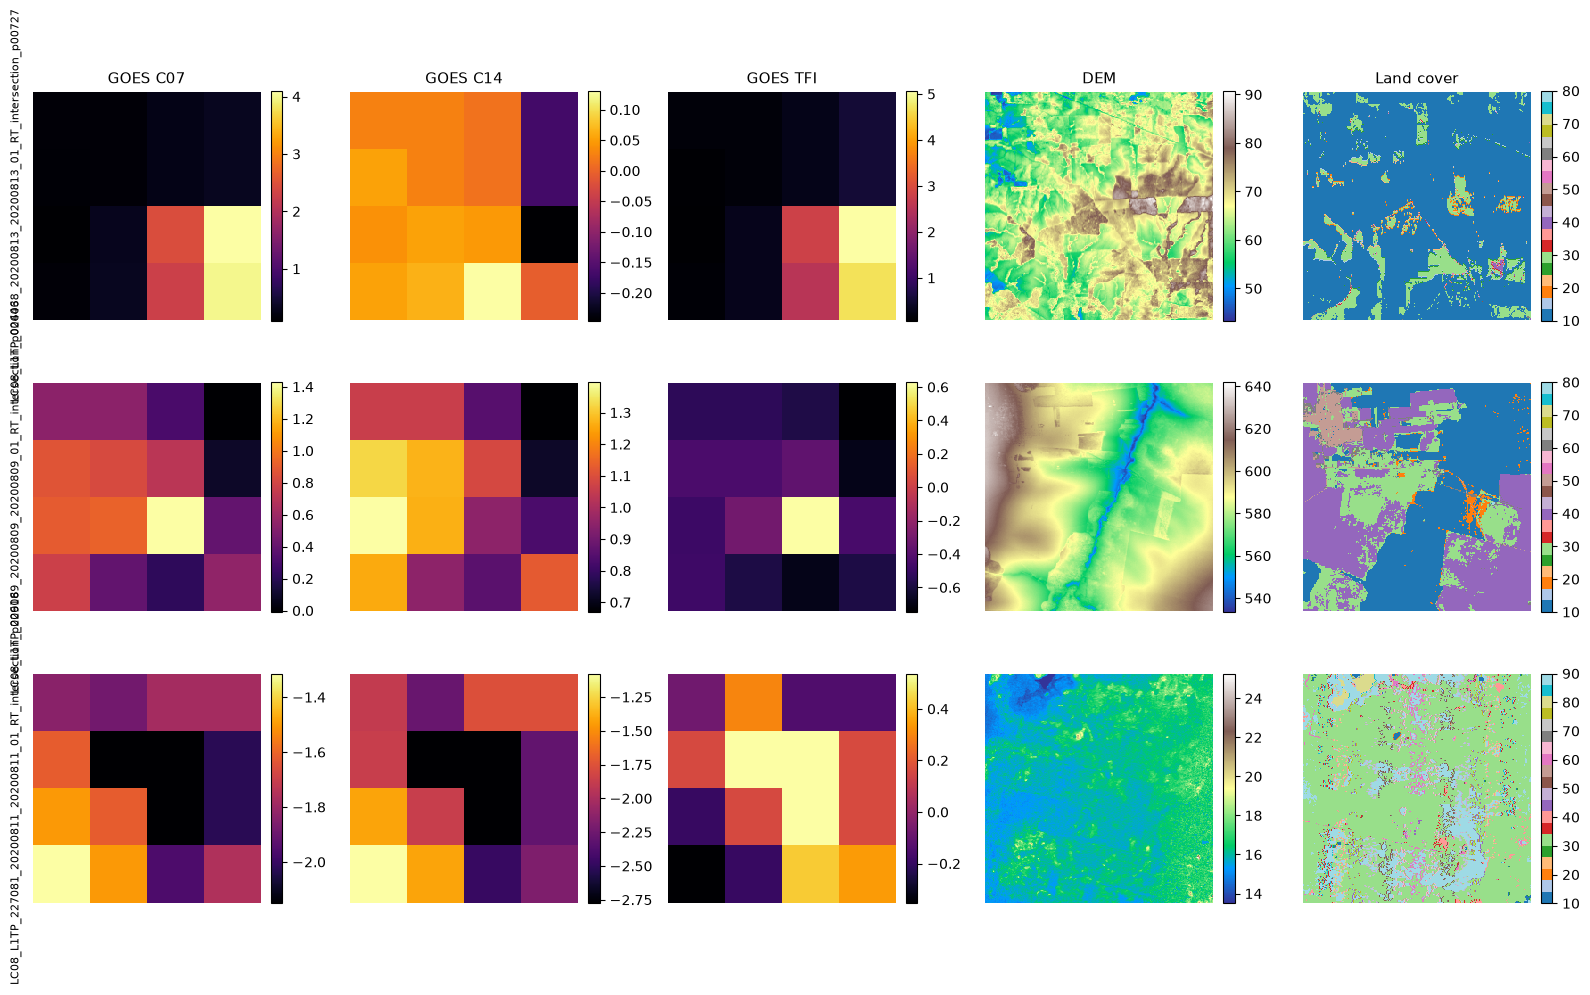

In [14]:
data = load_data_reference(
    config_path="../experiments/e1_haunet_direct.YAML",
    sample_ids=current_ids,
    split="test",
)
plot_input_reference_no_target(data, out=FIG_DIR/"input_reference.png")

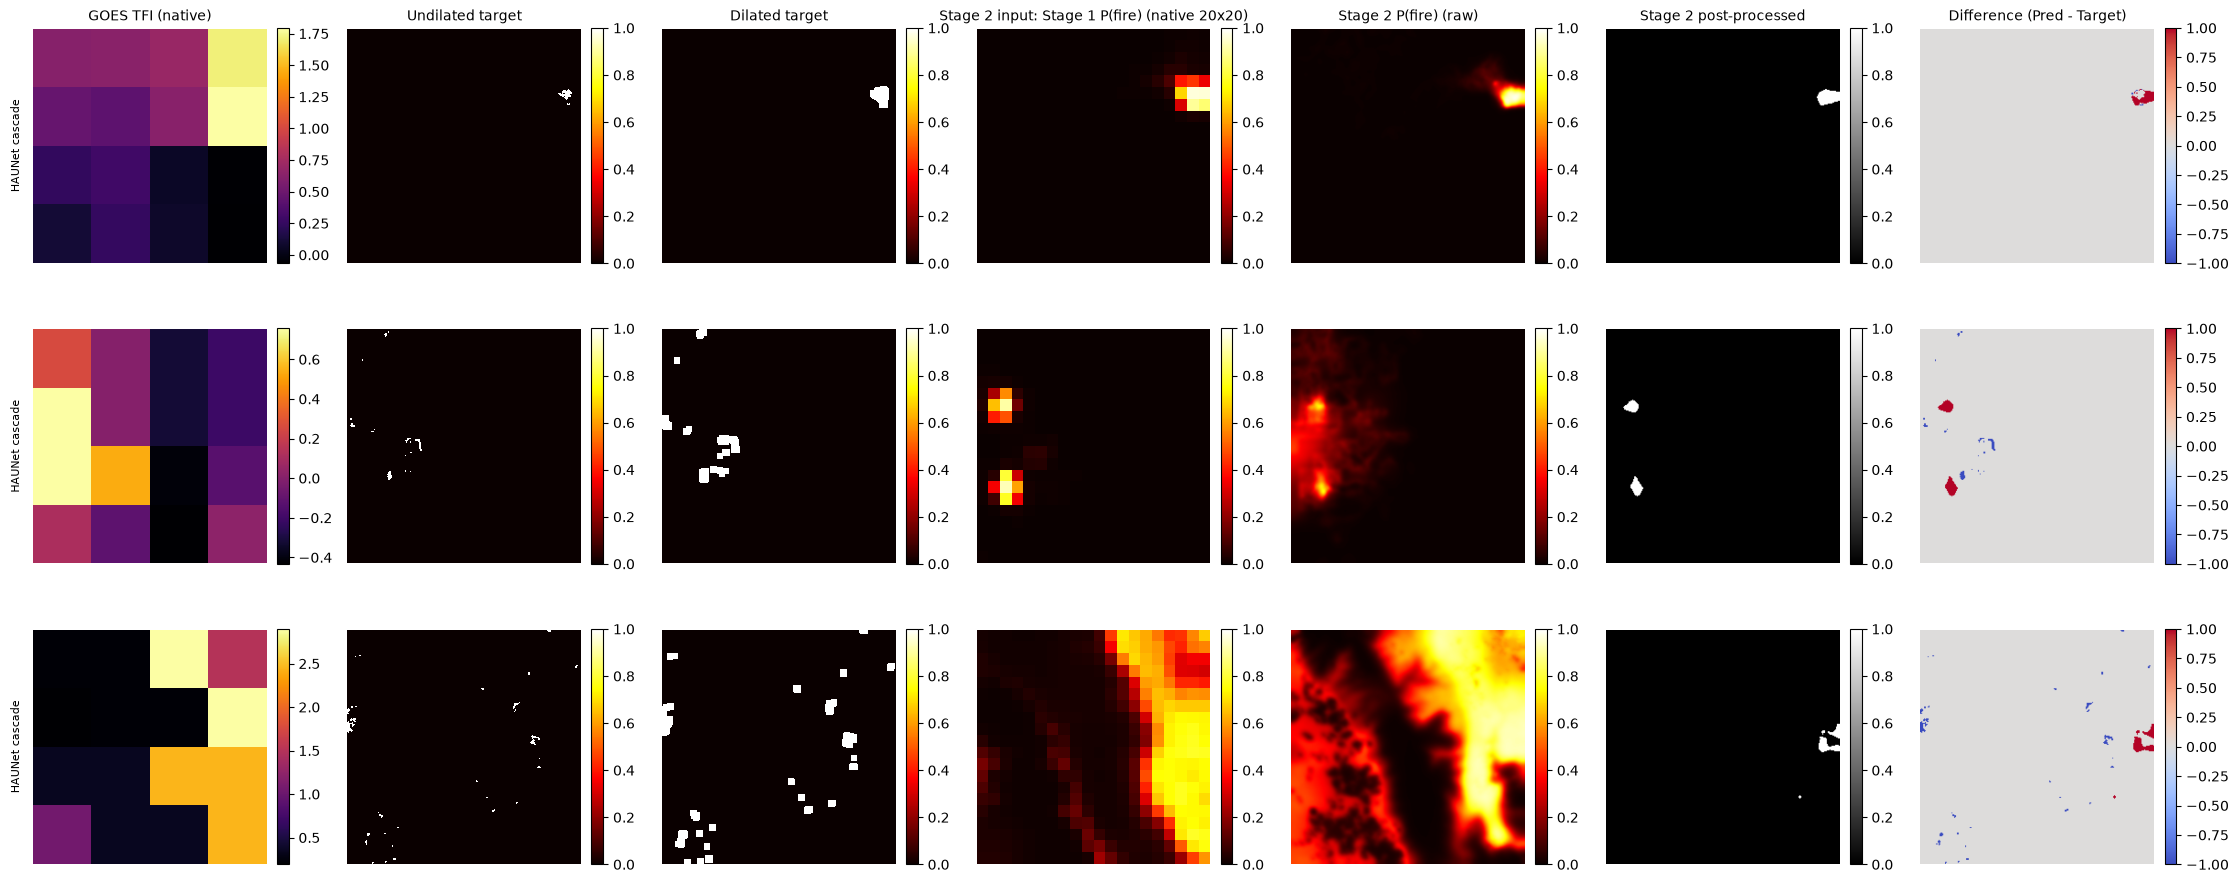

In [25]:
# Pick your sample_ids
ids_to_use = current_ids   # or: new_ids

cascade_result = run_cascade_live(
    ids_to_use,
    "../experiments/e2_haunet_cascaded_stage1.YAML",
    "../checkpoints/e2_haunet_cascaded_stage1_focal_dice/best_val_auprc.pt",
    "../experiments/e2_haunet_cascaded_stage2.YAML",
    "../checkpoints/e2_haunet_cascaded_stage2_focal_dice_single_dilated/best_val_auprc.pt",
    landsat_ds=ds,
    dilate_target=True, dilation_kernel_size=7,
)

plot_pipeline_panel(
    cascade_result,
    stage2_ds=ds,
    title_prefix="HAUNet cascade",
    out=FIG_DIR / "haunet_cascade_single_dilated_demo.png"
)

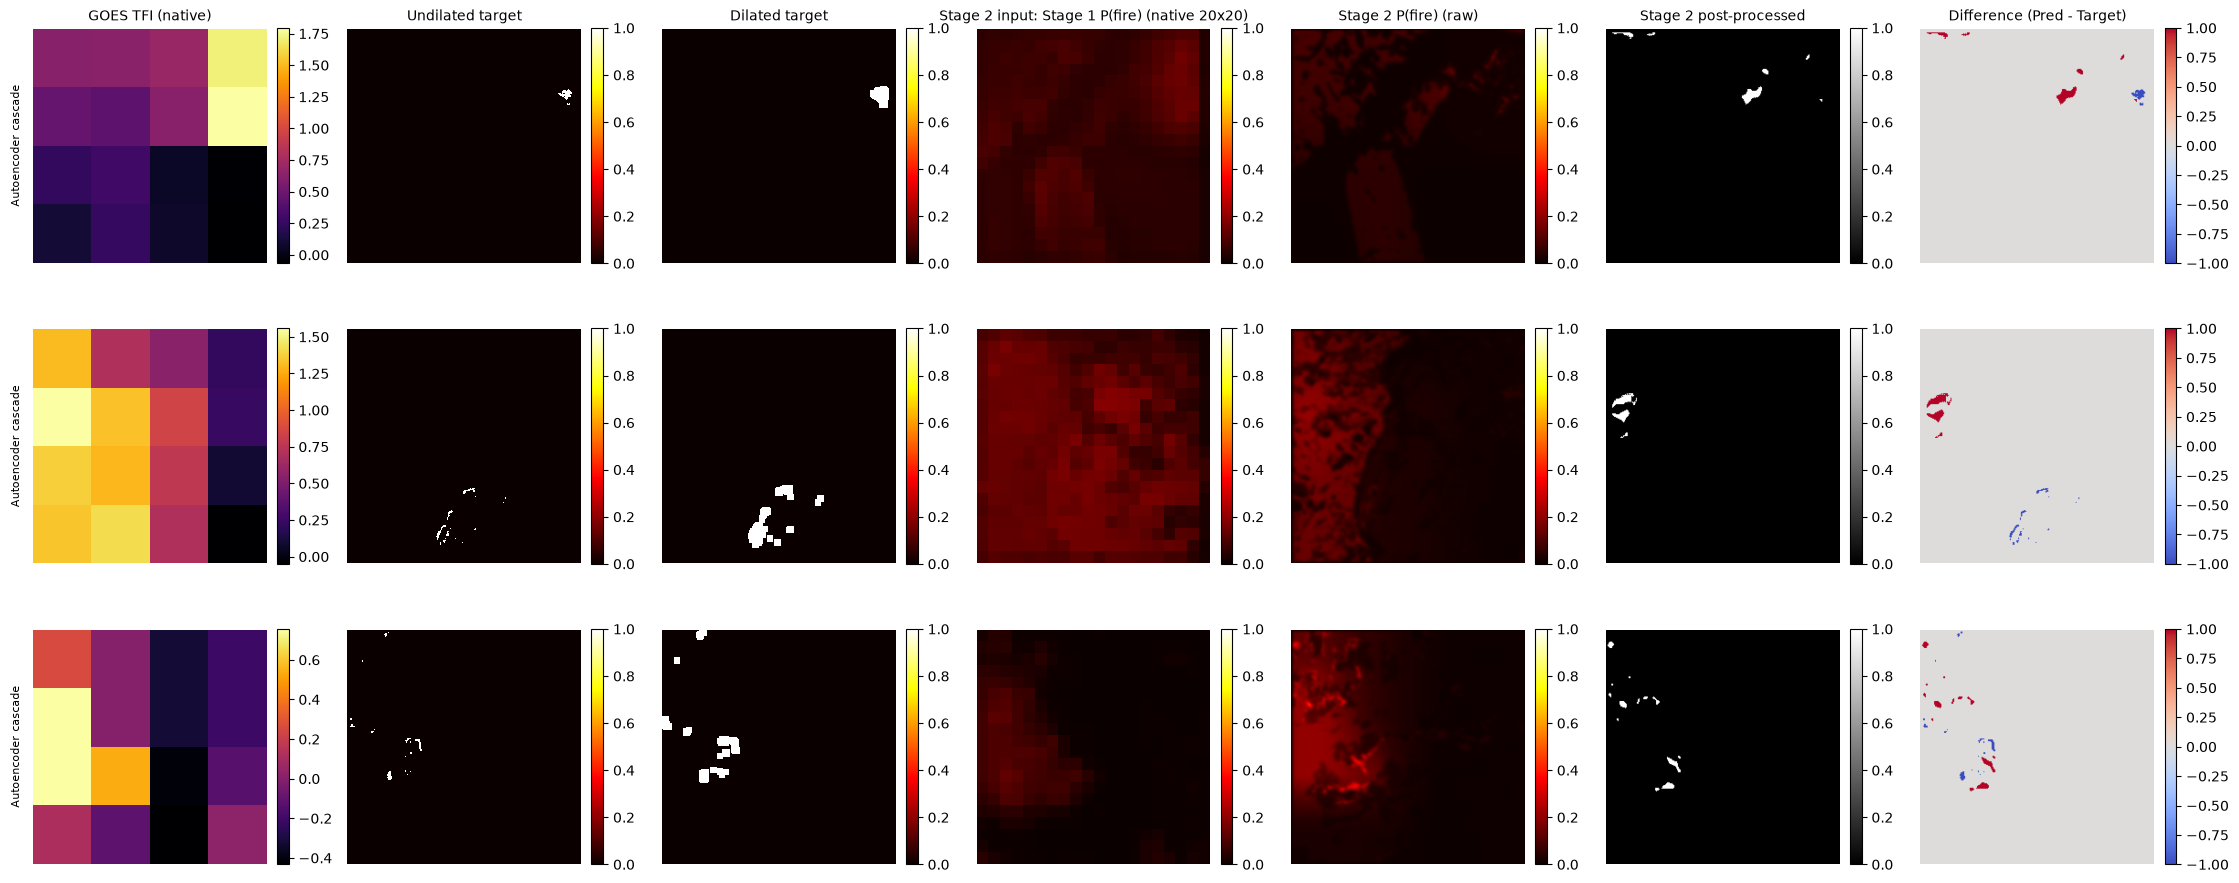

In [250]:
cascade_result_ae = run_cascade_live(
    current_ids,
    "../experiments/e4_autoencoder_cascaded_stage1.YAML",
    "../checkpoints/e4_autoencoder_cascaded_stage1_focal_dice/best_val_auprc.pt",
    "../experiments/e4_autoencoder_cascaded_stage2.YAML",
    "../checkpoints/e4_autoencoder_cascaded_stage2_focal_dice_dilated/best_val_auprc.pt",
    landsat_ds=ds,
    dilate_target=True, dilation_kernel_size=7,
)
plot_pipeline_panel(
    cascade_result_ae,
    stage2_ds=ds,
    title_prefix="Autoencoder cascade",
    out=FIG_DIR / "autoencoder_cascade_dilated.png"
)

[load_split_ids] Loaded 121 IDs for landsat/test
[WildfireDataset/landsat] Split filter: 121/121 samples in provided split.
[WildfireDataset/landsat] 121 usable pairs.
[WildfireDataset/landsat] sizes: target=(256, 256), cov=(256, 256), goes=(4, 4)
[WildfireDataset/landsat] Split filter: 121/121 samples in provided split.
[WildfireDataset/landsat] 121 usable pairs.
[WildfireDataset/landsat] sizes: target=(256, 256), cov=(256, 256), goes=(4, 4)
True 7


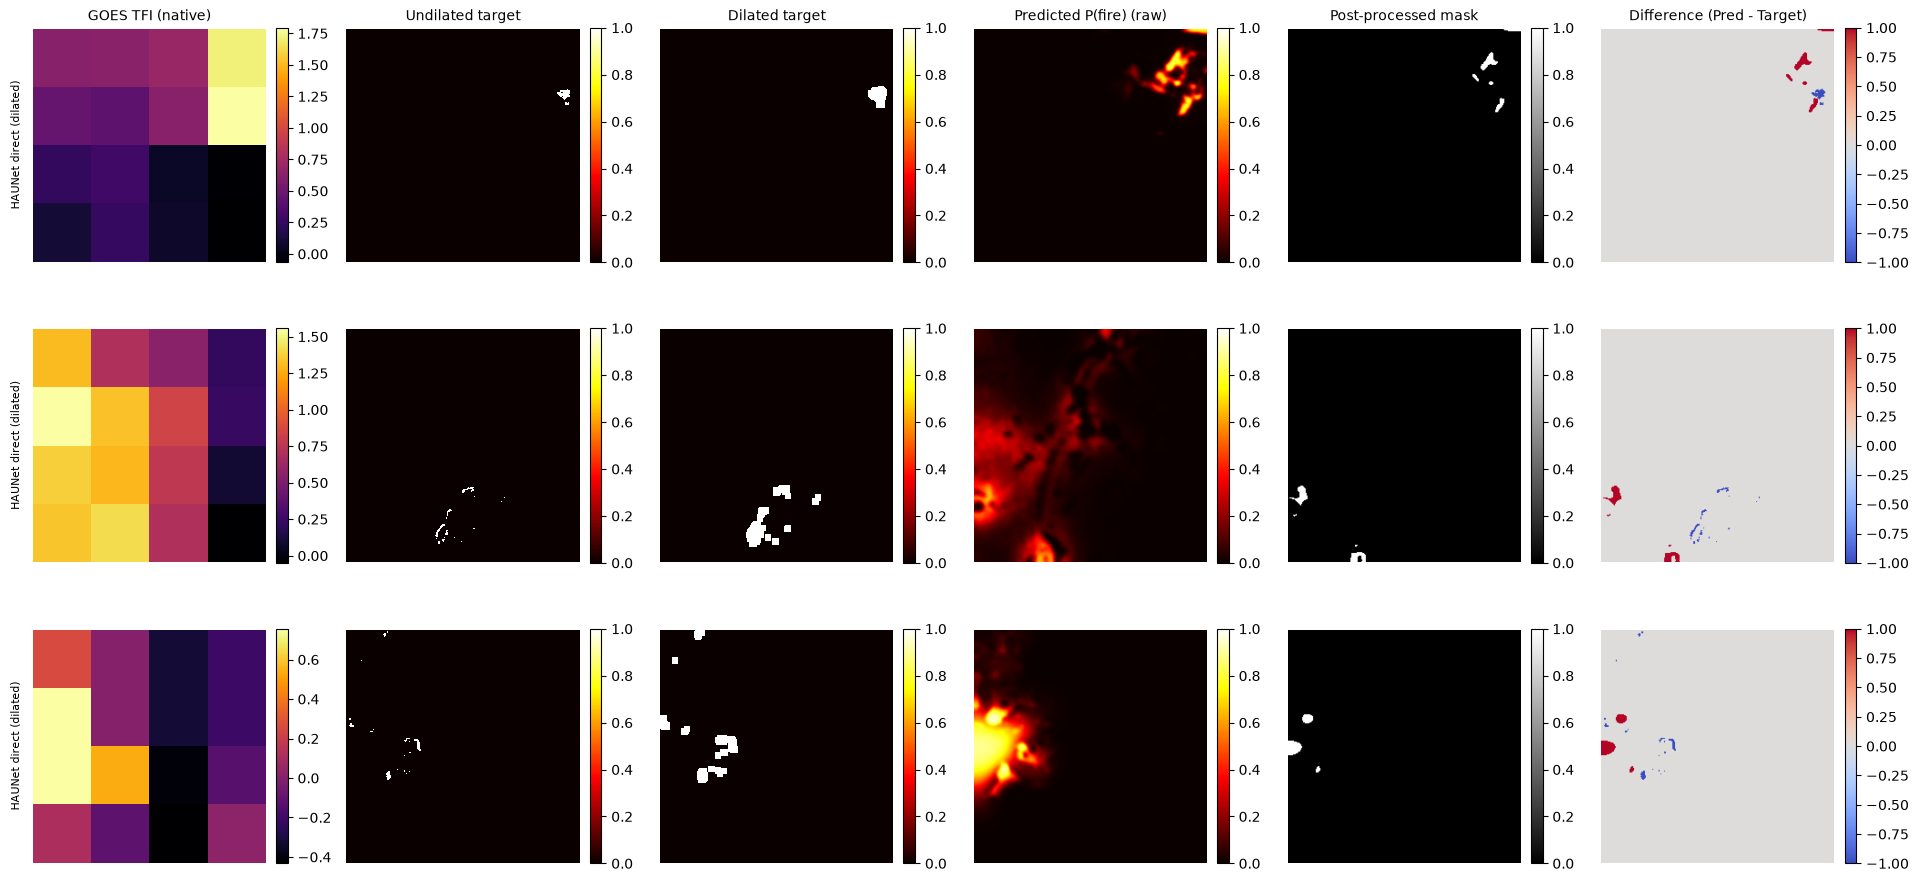

In [152]:
# ---- HAUNet direct (dilated) ----
e_haunet_direct = load_model_and_batch(
    "../experiments/e1_haunet_direct.YAML",
    "../checkpoints/e1_haunet_direct_focal_dice_dilated/best_val_auprc.pt",
    split="test", sample_ids=current_ids, load_undilated_target=True)

# Confirm dilation actually applied — should print True (and your intended kernel size)
print(cfg_check_dilate := yaml.safe_load(open("../experiments/e1_haunet_direct.YAML"))["data"].get("dilate_target"),
      yaml.safe_load(open("../experiments/e1_haunet_direct.YAML"))["data"].get("dilation_kernel_size"))

# Add GOES TFI for the input panel (channel 2 = TFI, native res from load_model_and_batch's "goes" key)
e_haunet_direct["goes_tfi"] = [e_haunet_direct["goes"][i, 2] for i in range(len(e_haunet_direct["sample_ids"]))]

plot_pipeline_panel(
    e_haunet_direct,
    title_prefix="HAUNet direct (dilated)",
    out=FIG_DIR / "haunet_direct_dilated.png"
)

[load_split_ids] Loaded 121 IDs for landsat/test
[WildfireDataset/landsat] Split filter: 121/121 samples in provided split.
[WildfireDataset/landsat] 121 usable pairs.
[WildfireDataset/landsat] sizes: target=(256, 256), cov=(256, 256), goes=(4, 4)
False None


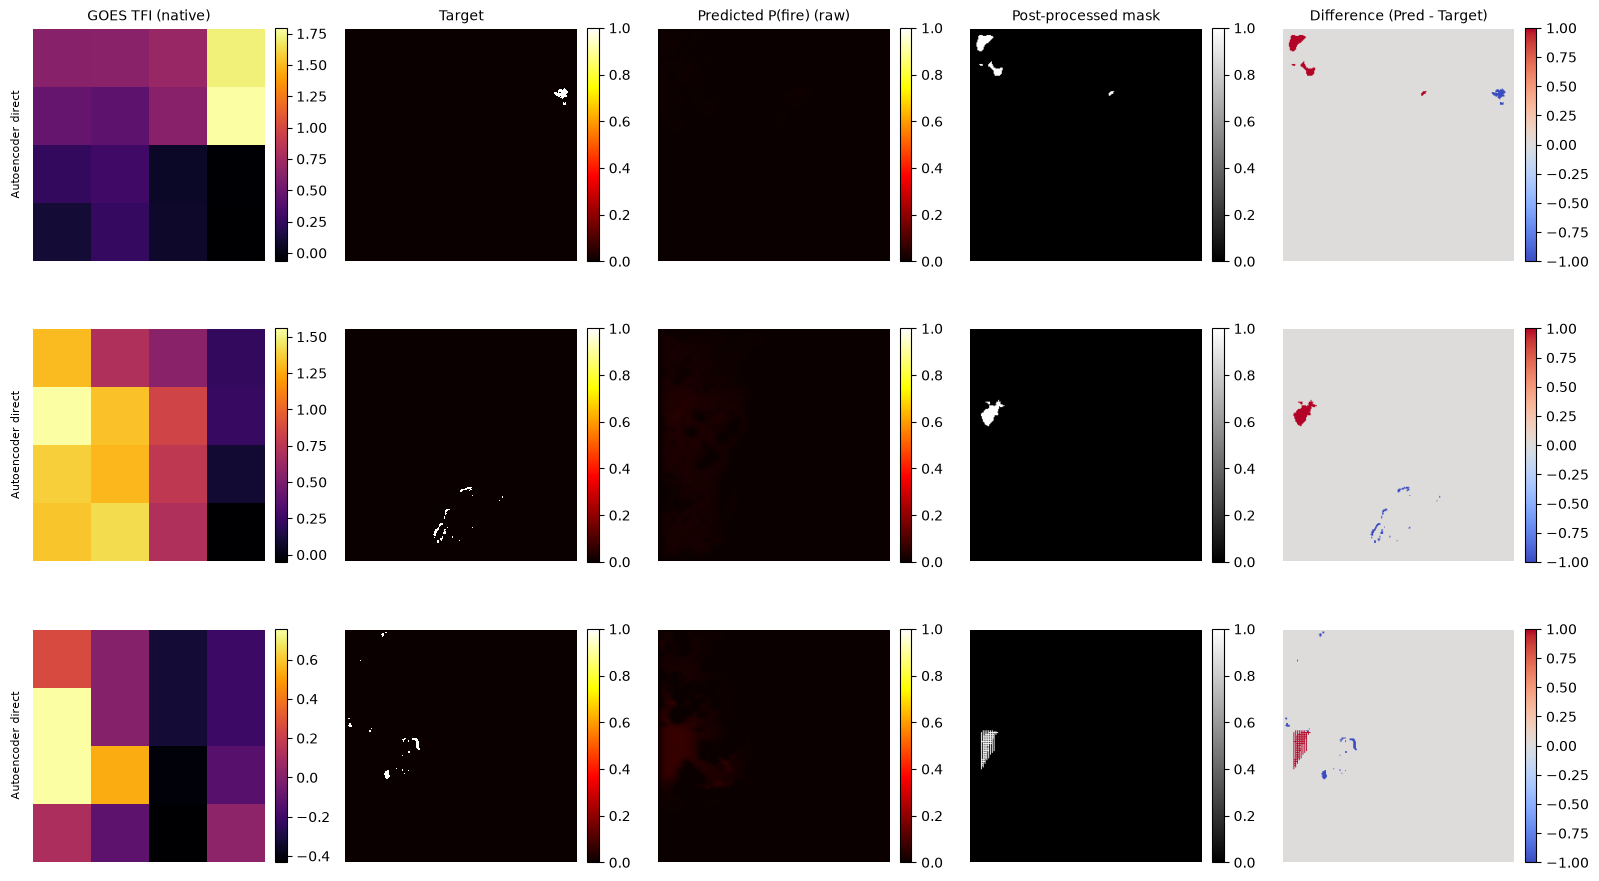

In [248]:
e_autoencoder_direct = load_model_and_batch(
    "../experiments/e3_autoencoder_direct.YAML",
    "../checkpoints/e3_autoencoder_direct_focal_dice/best_val_auprc.pt",
    split="test", sample_ids=current_ids, load_undilated_target=True)

print(cfg_check_dilate := yaml.safe_load(open("../experiments/e3_autoencoder_direct.YAML"))["data"].get("dilate_target"),
      yaml.safe_load(open("../experiments/e3_autoencoder_direct.YAML"))["data"].get("dilation_kernel_size"))

# Add GOES TFI for the input panel (channel 2 = TFI, native res from load_model_and_batch's "goes" key)
e_autoencoder_direct["goes_tfi"] = [e_haunet_direct["goes"][i, 2] for i in range(len(e_haunet_direct["sample_ids"]))]

plot_pipeline_panel(
    e_autoencoder_direct,
    title_prefix="Autoencoder direct",
    out=FIG_DIR / "autoencoder_direct.png"
)

In [47]:
def plot_pipeline_panel(batch_data, stage2_ds=None, title_prefix="", out=None, row_labels=None):
    """
    Plots only 3 panels: GOES Input, VIIRS Target (undilated), and Predicted VIIRS Output.
    """
    stage1_native = batch_data.get("stage1_probs_native")
    has_goes = "goes_tfi" in batch_data
    has_undilated = batch_data.get("undilated_target") is not None
    target = batch_data["target"]

    n = target.shape[0]

    # Define exact columns requested
    col_titles = []
    if has_goes:
        col_titles.append("GOES TFI Input")
    col_titles.append("VIIRS Target")
    
    if stage1_native is not None:
        h, w = stage1_native[0].shape[-2:]
        col_titles.append(f"Predicted VIIRS P(fire) ({w}x{h})")
    else:
        col_titles.append("Predicted VIIRS P(fire)")

    n_cols = len(col_titles)
    fig, axes = plt.subplots(n, n_cols, figsize=(3.2 * n_cols, 3.1 * n))
    if n == 1:
        axes = axes[np.newaxis, :]

    for row in range(n):
        panels, cmaps, clims, interps = [], [], [], []

        # 1. GOES Input Panel
        if has_goes:
            goes_val = batch_data["goes_tfi"][row]
            goes_val = goes_val.cpu().numpy() if torch.is_tensor(goes_val) else goes_val
            panels.append(goes_val)
            cmaps.append("inferno"); clims.append((None, None)); interps.append("nearest")

        # 2. VIIRS Target Panel (Undilated raw GT)
        vt = (batch_data["undilated_target"][row, 0].cpu().numpy()
              if has_undilated else target[row, 0].cpu().numpy())
        panels.append(vt)
        cmaps.append("hot"); clims.append((0, 1)); interps.append("nearest")

        # 3. Predicted VIIRS Output Panel (Stage 1 Native Probs)
        if stage1_native is not None:
            s1_val = stage1_native[row][0].numpy() if torch.is_tensor(stage1_native[row]) else stage1_native[row][0]
        else:
            s1_val = batch_data["probs"][row, 0].cpu().numpy()
            
        panels.append(s1_val)
        cmaps.append("hot"); clims.append((0, 1)); interps.append("nearest")

        # Render rows
        for col in range(n_cols):
            ax = axes[row, col]
            im = ax.imshow(panels[col], cmap=cmaps[col], vmin=clims[col][0], vmax=clims[col][1],
                            interpolation=interps[col])
            if row == 0:
                ax.set_title(col_titles[col], fontsize=10)
            ax.set_xticks([]); ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        label = row_labels[row] if row_labels else title_prefix
        axes[row, 0].set_ylabel(label, fontsize=8, rotation=90, labelpad=8)

    plt.tight_layout()
    if out:
        plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()

In [31]:
import random

def find_ids_with_min_fire_pixels(viirs_ds, min_pixels=20, n_ids=3, seed=None, max_scan=None):
    candidates = []
    samples_to_scan = viirs_ds.samples if max_scan is None else viirs_ds.samples[:max_scan]

    for manifest in samples_to_scan:
        # Read the VIIRS target raster from GCS
        target = viirs_ds._read_gcs_raster(manifest["paths"]["target"])
        
        # Count non-zero/active fire pixels
        active_pixels = (target > 0).sum().item()
        if active_pixels > min_pixels:
            candidates.append((manifest["id"], active_pixels))

    print(f"Found {len(candidates)} samples with > {min_pixels} active target pixels "
          f"(out of {len(samples_to_scan)} scanned).")

    if not candidates:
        return []

    if seed is not None:
        random.seed(seed)
    chosen = random.sample(candidates, min(n_ids, len(candidates)))

    chosen_ids = [c[0] for c in chosen]
    print("Selected VIIRS IDs (id, active_pixel_count):")
    for cid, count in chosen:
        print(f"  {cid}: {count}")

    return chosen_ids

In [39]:
from src.data.wildfire_dataset import load_split_ids, WildfireDataset

bucket_name = data_cfg.get("bucket_name", "wildfire-irp-data-th25")
prefix = data_cfg.get("output_prefix", "processed_dataset_gcp")

# Pass positional arguments: (bucket_name, branch, split, prefix)
split_ids = load_split_ids(
    bucket_name,
    "viirs",
    "val",
    prefix
)

# Instantiate dataset
viirs_ds = WildfireDataset(
    bucket_name=bucket_name,
    output_prefix=prefix,
    branch="viirs",
    split_ids=split_ids,
    dilate_target=data_cfg.get("dilate_target", True),
    dilation_kernel_size=data_cfg.get("dilation_kernel_size", 7)
)

[load_split_ids] Loaded 1563 IDs for viirs/val
[WildfireDataset/viirs] Split filter: 1563/1563 samples in provided split.
[WildfireDataset/viirs] 1563 usable pairs.
[WildfireDataset/viirs] sizes: target=(20, 20), cov=(256, 256), goes=(4, 4)


In [46]:
# 1. Filter IDs with min fire pixels using the VIIRS dataset
new_ids = find_ids_with_min_fire_pixels(viirs_ds, min_pixels=15, n_ids=3)
ids_to_use = new_ids

Found 25 samples with > 15 active target pixels (out of 1563 scanned).
Selected VIIRS IDs (id, active_pixel_count):
  20200805T1700_-838_-274: 37
  20200622T1730_-853_-369: 16
  20200718T1730_-872_-481: 18


In [49]:
new_ids = find_ids_with_min_fire_pixels(viirs_ds, min_pixels=20, n_ids=3)
ids_to_use = new_ids

Found 12 samples with > 20 active target pixels (out of 1563 scanned).
Selected VIIRS IDs (id, active_pixel_count):
  20200624T0430_-831_-172: 22
  20200124T1800_-876_-237: 23
  20200422T0730_-1292_245: 33


In [53]:
new_ids = find_ids_with_min_fire_pixels(viirs_ds, min_pixels=15, n_ids=3)
ids_to_use = new_ids

Found 25 samples with > 15 active target pixels (out of 1563 scanned).
Selected VIIRS IDs (id, active_pixel_count):
  20200619T0900_-1606_470: 46
  20200406T1630_-834_-269: 16
  20200126T0600_-941_145: 19


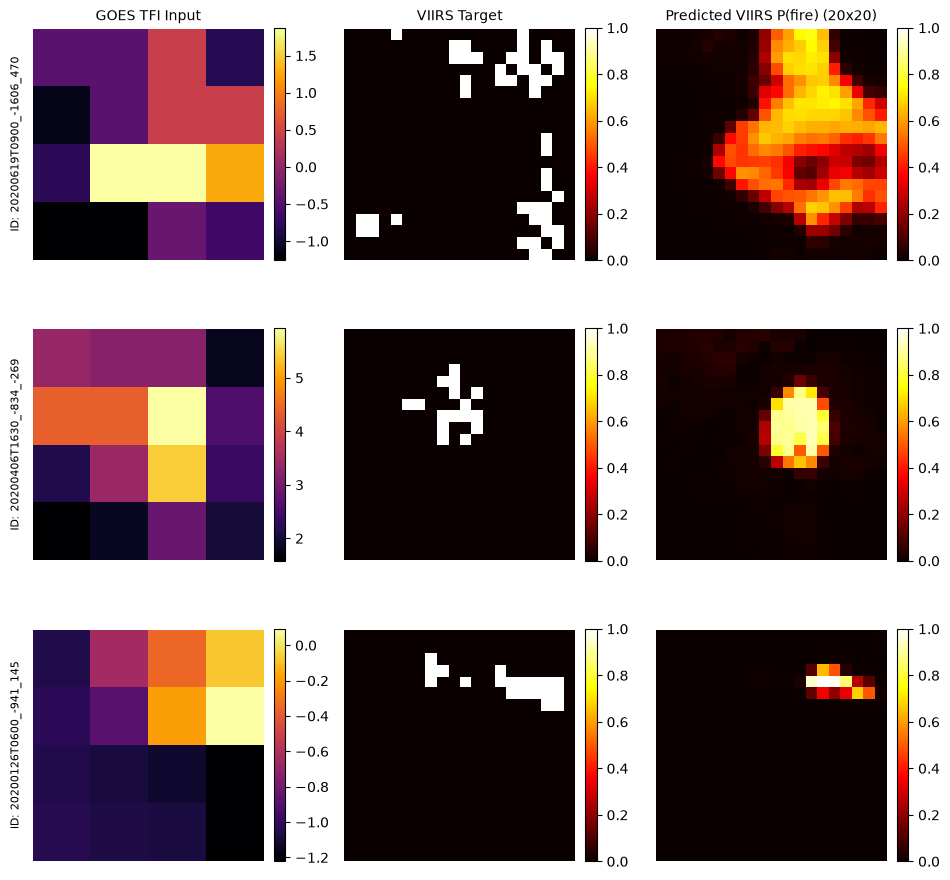

In [54]:
# 2. Run the live cascade pipeline with VIIRS dataset
cascade_result = run_cascade_live(
    ids_to_use,
    "../experiments/e2_haunet_cascaded_stage1.YAML",
    "../checkpoints/e2_haunet_cascaded_stage1_focal_dice/best_val_auprc.pt",
    "../experiments/e2_haunet_cascaded_stage2.YAML",
    "../checkpoints/e2_haunet_cascaded_stage2_focal_dice_single_dilated/best_val_auprc.pt",
    landsat_ds=viirs_ds,  # Key change: keep keyword as landsat_ds
    dilate_target=True, 
    dilation_kernel_size=7,
)

# 3. Plot GOES input, VIIRS target, and Predicted VIIRS output
plot_pipeline_panel(
    cascade_result,
    stage2_ds=viirs_ds,
    title_prefix="HAUNet VIIRS Cascade",
    row_labels=[f"ID: {sid}" for sid in ids_to_use],
    out=FIG_DIR / "haunet_cascade_viirs_demo_3.png"
)